# Pengendalian Mutu *Injection Molding*

Notebook ini berisi pengerjaan saya untuk Kasus 01. Klien adalah kepala bagian *quality control* (QC) di pabrik
komponen plastik di Cikarang. Saat ini komponen cacat baru ketahuan saat inspeksi visual di akhir shift,
sehingga ratusan komponen bisa telanjur cacat sebelum pengaturan mesin diperbaiki.

Tujuan saya adalah membuat model yang menerima parameter dari satu siklus cetak, lalu memberikan probabilitas
bahwa komponen tersebut cacat. Hasil akhirnya berupa tiga file, yaitu `artifacts/model.joblib`,
`artifacts/metadata.json`, dan `src/features.py`. Ketiga file ini nantinya dipakai oleh API dan aplikasi untuk
operator mesin.

| Bagian | Isi |
|---|---|
| 1 | Setup |
| 2 | Mengenal data |
| 3 | Membersihkan data |
| 4 | EDA terhadap target (cacat) |
| 5 | Membuat fitur dari pengetahuan proses (`src/features.py`) |
| 6 | Membagi data menjadi train, validation, dan test |
| 7 | *Baseline* wajib berupa regresi logistik |
| 8 | Model lain |
| 9 | Memilih *threshold* berdasarkan biaya, lalu membuka data test |
| 10 | Menyimpan model dan mengujinya dari file |

Di beberapa langkah saya menambahkan sel **✅ Cek** yang berisi `assert`. Sel ini memastikan hasil langkah
sebelumnya sesuai harapan, sehingga jika ada yang salah, notebook langsung berhenti tepat di langkah yang bermasalah.

## 1 · Setup

Saya memuat library, menentukan lokasi root repo, lalu membaca data mentah. Di sini saya juga menyimpan suhu
standar dari tim proses (PP 230/40 °C, ABS 240/60 °C, PC 300/90 °C) dan daftar bahan yang menyerap air,
karena keduanya akan dipakai berkali-kali di bagian berikutnya.

In [1]:
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# root repo = folder yang berisi data/raw.csv, yaitu folder kerja sekarang atau satu tingkat di atasnya
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "data" / "raw.csv").exists()), None)
assert ROOT is not None, "data/raw.csv tidak ditemukan. Jalankan dari root repo atau dari folder notebooks/."
DATA_PATH = ROOT / "data" / "raw.csv"

(ROOT / "src").mkdir(exist_ok=True)
(ROOT / "artifacts").mkdir(exist_ok=True)
(ROOT / "src" / "__init__.py").touch()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RANDOM_STATE = 42
TARGET = "cacat"

# suhu standar dari tim proses: (suhu leleh, suhu cetakan) dalam °C
SUHU_STANDAR = {"PP": (230, 40), "ABS": (240, 60), "PC": (300, 90)}
BAHAN_HIGROSKOPIS = {"ABS", "PC"}

df_mentah = pd.read_csv(DATA_PATH)
df = df_mentah.copy()   # df_mentah disimpan untuk perbandingan sebelum dan sesudah dibersihkan
print(f"Root repo: {ROOT}\ndata/raw.csv: {len(df):,} baris, {df.shape[1]} kolom")
df.head()

Root repo: c:\Users\LOQ\Downloads\qc-injection-molding
data/raw.csv: 25,350 baris, 12 kolom


,waktu_produksi,mesin,shift,bahan,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
0,2026-03-01 00:12:45,IM-02,siang,PC,302.0,74.2,1053.0,68.6,15.1,27.5,0.088,0
1,2026-03-01 00:14:38,IM-01,pagi,P.P,219.6,40.1,1143.0,89.2,28.7,39.8,0.021,0
2,2026-03-01 00:19:00,IM-01,siang,ABS,230.6,67.7,945.0,89.2,15.2,29.2,0.046,0
3,2026-03-01 00:53:09,IM-01,malam,ABS,245.0,64.0,905.0,88.4,12.0,25.0,0.027,0
4,2026-03-01 01:07:19,IM-03,siang,PP,242.5,33.2,908.0,76.5,22.5,38.7,0.011,0


## 2 · Mengenal data

Sebelum melatih model, saya perlu tahu dulu seperti apa isi datanya. Setiap baris mewakili satu siklus cetak,
atau satu komponen, dari empat mesin selama Maret sampai Juni 2026. Arti setiap kolom adalah sebagai berikut.

| Kolom | Arti |
|---|---|
| `waktu_produksi` | waktu siklus cetak |
| `mesin` | IM-01 sampai IM-04 |
| `shift` | pagi, siang, malam |
| `bahan` | jenis plastik: PP, ABS, atau PC |
| `suhu_leleh_C` | suhu plastik cair di dalam *barrel* (°C) |
| `suhu_cetakan_C` | suhu cetakan (°C) |
| `tekanan_injeksi_bar` | tekanan saat plastik disuntikkan (bar) |
| `kecepatan_injeksi_mm_s` | kecepatan dorong *screw* (mm/detik) |
| `waktu_pendinginan_s` | lama komponen didinginkan di dalam cetakan (detik) |
| `waktu_siklus_s` | lama satu siklus penuh (detik) |
| `kelembaban_bahan_pct` | kadar air bahan sebelum dicetak (%) |
| `cacat` | **target**: 1 = cacat, 0 = lolos QC |

Data ini diekspor apa adanya dari sistem klien dan belum diperiksa oleh siapa pun. Karena itu, di bagian ini
saya mencari dua jenis keanehan. Jenis pertama adalah nilai yang **pasti salah**, misalnya nilai yang mustahil secara
fisik, salah satuan, atau salah ketik. Jenis kedua adalah nilai yang **aneh tetapi masih mungkin terjadi**, yaitu
nilai yang jarang muncul dan ekstrem, tetapi bisa saja benar.

### 2.1 Tipe data
Saya mulai dengan memeriksa tipe data dan jumlah nilai yang terisi di setiap kolom.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25350 entries, 0 to 25349
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   waktu_produksi          25350 non-null  str    
 1   mesin                   25350 non-null  str    
 2   shift                   25350 non-null  str    
 3   bahan                   25350 non-null  str    
 4   suhu_leleh_C            25350 non-null  float64
 5   suhu_cetakan_C          25350 non-null  float64
 6   tekanan_injeksi_bar     25350 non-null  float64
 7   kecepatan_injeksi_mm_s  25350 non-null  float64
 8   waktu_pendinginan_s     25093 non-null  float64
 9   waktu_siklus_s          25350 non-null  float64
 10  kelembaban_bahan_pct    24342 non-null  float64
 11  cacat                   25350 non-null  int64  
dtypes: float64(7), int64(1), str(4)
memory usage: 3.1 MB


Semua kolom parameter proses sudah bertipe angka, dan kolom target tidak memiliki nilai kosong. Ada dua kolom,
yaitu `waktu_pendinginan_s` dan `kelembaban_bahan_pct`, yang jumlah nilai terisinya lebih sedikit daripada jumlah
baris. Artinya kedua kolom ini memiliki nilai kosong, yang saya hitung di bagian 2.5. Kolom `waktu_produksi` masih
tersimpan sebagai teks, jadi saya mengubahnya ke tipe `datetime` agar bisa dipakai untuk analisis berdasarkan waktu.

In [3]:
df["waktu_produksi"] = pd.to_datetime(df["waktu_produksi"], errors="coerce")
print("Waktu yang gagal dibaca:", df["waktu_produksi"].isna().sum())
print("Rentang waktu:", df["waktu_produksi"].min(), "s.d.", df["waktu_produksi"].max())

Waktu yang gagal dibaca: 0
Rentang waktu: 2026-03-01 00:12:45 s.d. 2026-06-28 23:45:48


Semua nilai waktu berhasil dibaca, dan datanya mencakup produksi dari awal Maret sampai akhir Juni 2026.

### 2.2 Ringkasan angka
Selanjutnya saya melihat ringkasan statistik setiap kolom angka. Bagian yang paling saya perhatikan adalah nilai
minimum dan maksimum, karena nilai yang mustahil biasanya muncul di sana.

In [4]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
waktu_produksi,25350,2026-04-30 00:52:32.057869,2026-03-01 00:12:45,2026-03-31 03:44:08.750000,2026-04-29 22:37:02,2026-05-30 00:29:38.750000,2026-06-28 23:45:48,NaN
suhu_leleh_C,25350.0,253.681763,194.9,229.9,238.7,254.0,615.2,44.985577
suhu_cetakan_C,25350.0,56.132951,8.0,39.9,51.2,67.0,113.7,20.39535
tekanan_injeksi_bar,25350.0,896.200118,0.0,825.0,900.0,973.0,1310.0,126.415365
kecepatan_injeksi_mm_s,25350.0,79.867278,25.6,69.8,79.8,90.0,139.2,14.991186
waktu_pendinginan_s,25093.0,18.022389,6.0,15.3,18.0,20.7,35.1,3.985908
waktu_siklus_s,25350.0,31.901381,-1.0,29.0,32.0,35.0,50.0,4.791069
kelembaban_bahan_pct,24342.0,0.054674,0.0,0.015,0.033,0.076,0.514,0.057146
cacat,25350.0,0.078067,0.0,0.0,0.0,0.0,1.0,0.268282


Ada tiga hal yang langsung terlihat janggal. Tekanan injeksi minimumnya 0 bar, padahal plastik tidak mungkin
disuntikkan ke cetakan tanpa tekanan. Waktu siklus minimumnya −1 detik, padahal waktu tidak mungkin bernilai
negatif. Suhu leleh maksimumnya 615 °C, jauh di atas suhu standar tertinggi, yaitu sekitar 300 °C untuk PC.

### 2.3 Kolom kategori
Saya memeriksa isi setiap kolom kategori untuk melihat apakah penulisannya sudah seragam.

In [5]:
for kolom in ["mesin", "shift", "bahan"]:
    print(f"--- {kolom}")
    print(df[kolom].value_counts(dropna=False).to_string(), "\n")

--- mesin
mesin
IM-01    7593
IM-02    7571
IM-04    5101
IM-03    5085 

--- shift
shift
pagi      9996
siang     8726
malam     6122
SIANG      175
malam      170
Pagi       161 

--- bahan
bahan
PP      12210
ABS      7410
PC       4969
PP        134
P.P       130
pp        130
PC         80
abs        79
pc         75
ABS        73
Abs        60 



Kolom `mesin` sudah rapi, tetapi kolom `shift` dan `bahan` belum seragam. Misalnya ada `SIANG`, `malam` dengan spasi
di belakangnya, `P.P`, `pp`, dan `Abs`. Bagi komputer, setiap variasi penulisan ini dianggap sebagai kategori yang
berbeda, sehingga perlu saya rapikan di bagian 3.

### 2.4 Ringkasan angka per bahan
Rentang suhu yang wajar berbeda untuk setiap bahan. Suhu leleh 300 °C normal untuk PC, tetapi terlalu tinggi untuk
PP. Karena itu saya juga melihat statistiknya per bahan. Nama bahan saya rapikan sementara hanya untuk tampilan ini,
sedangkan kolom aslinya baru saya ubah di bagian 3.

In [6]:
bahan_sementara = df["bahan"].str.strip().str.upper().str.replace(".", "", regex=False)
kolom_lihat = ["suhu_leleh_C", "suhu_cetakan_C", "kelembaban_bahan_pct"]
df.groupby(bahan_sementara)[kolom_lihat].describe().T.round(2)

bahan                           ABS       PC        PP
suhu_leleh_C         count  7622.00  5124.00  12604.00
                     mean    245.61   307.68    236.61
                     std      32.57    41.10     35.02
                     min     207.10   271.00    194.90
                     25%     234.90   295.60    225.00
                     50%     241.40   301.80    231.40
                     75%     248.00   308.30    238.10
                     max     508.60   615.20    483.10
suhu_cetakan_C       count  7622.00  5124.00  12604.00
                     mean     60.09    90.04     39.96
                     std       7.01     7.03      6.94
                     min      35.20    63.80      8.00
                     25%      55.40    85.50     35.20
                     50%      60.10    90.10     39.90
                     75%      64.70    94.80     44.60
                     max      88.20   113.70     70.00
kelembaban_bahan_pct count  7309.00  4908.00  12125.00
                     mean      0.09     0.09      0.02
                     std       0.06     0.06      0.01
                     min       0.00     0.00      0.00
                     25%       0.04     0.04      0.01
                     50%       0.08     0.08      0.02
                     75%       0.12     0.12      0.03
                     max       0.44     0.51      0.15

Rata-rata suhu leleh dan suhu cetakan setiap bahan sudah dekat dengan suhu standar dari tim proses. Namun suhu leleh
maksimum setiap bahan berada ratusan derajat di atas standarnya, sehingga perlu saya telusuri di bagian 2.7.
Kelembaban PP juga jauh lebih rendah daripada ABS dan PC. Hal ini sesuai dengan informasi dari tim proses bahwa ABS dan PC
menyerap air, sedangkan PP tidak.

### 2.5 Nilai kosong dan duplikat

In [7]:
kosong = df.isna().sum()
print("Nilai kosong per kolom:")
print(kosong[kosong > 0].to_string(), "\n")
print("Baris duplikat (semua kolom sama persis):", df.duplicated().sum())

Nilai kosong per kolom:
waktu_pendinginan_s      257
kelembaban_bahan_pct    1008 

Baris duplikat (semua kolom sama persis): 350


Ada 1.008 nilai kosong di kelembaban bahan dan 257 nilai kosong di waktu pendinginan. Selain itu ada 350 baris yang
sama persis di semua kolom. Kemungkinan besar satu siklus tercatat dua kali saat data diekspor dari sistem klien.

### 2.6 Proporsi komponen cacat
Angka ini menentukan metrik yang cocok untuk menilai model.

In [8]:
rasio_cacat = df[TARGET].mean()
print(f"Proporsi cacat                            : {rasio_cacat:.1%}")
print(f"Akurasi model yang selalu menjawab 'lolos': {1 - rasio_cacat:.1%}")

Proporsi cacat                            : 7.8%
Akurasi model yang selalu menjawab 'lolos': 92.2%


Hanya sekitar 8% komponen yang cacat. Akibatnya, model yang tidak belajar apa pun dan selalu menjawab "lolos" sudah
mendapat akurasi di atas 90%, padahal model itu tidak pernah menangkap satu pun komponen cacat. Karena itu akurasi
tidak bisa saya pakai untuk menilai model. Sebagai gantinya saya memakai PR-AUC, yang hanya bernilai tinggi jika model berhasil
menangkap komponen cacat tanpa terlalu banyak alarm palsu. Sebagai patokan, model yang menebak secara acak akan
mendapat PR-AUC kira-kira sama dengan proporsi cacat, yaitu sekitar 0,08.

### 2.7 Suhu leleh per mesin sepanjang waktu
Untuk mencari asal suhu leleh di atas 400 °C, saya membuat plot suhu leleh terhadap waktu untuk setiap mesin.
Jika penyebabnya adalah sensor yang rusak secara acak, titik yang janggal akan tersebar di mana-mana. Jika titik
yang janggal muncul berkelompok di satu mesin dan satu periode, kemungkinan besar penyebabnya sistematis.

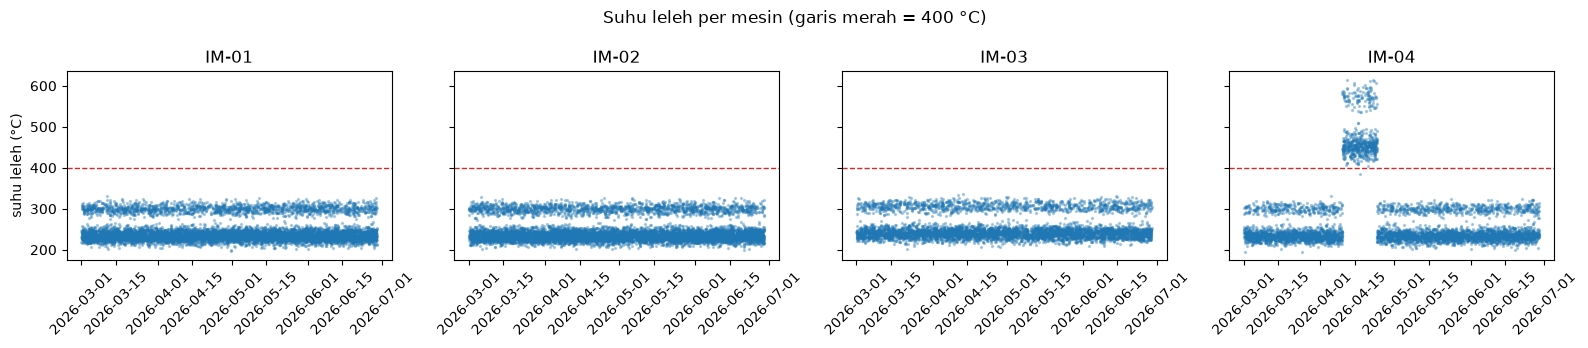

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, (mesin, bagian) in zip(axes, df.groupby("mesin")):
    ax.scatter(bagian["waktu_produksi"], bagian["suhu_leleh_C"], s=2, alpha=0.3)
    ax.axhline(400, color="tab:red", linestyle="--", linewidth=1)
    ax.set_title(mesin)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("suhu leleh (°C)")
fig.suptitle("Suhu leleh per mesin (garis merah = 400 °C)")
plt.tight_layout()
plt.show()

Semua titik di atas 400 °C berasal dari IM-04 dan hanya muncul dalam satu periode pendek di bulan April. Tidak ada
bahan di pabrik ini yang dicetak pada suhu setinggi itu, jadi angka tersebut bukan suhu yang sebenarnya. Dugaan saya,
selama periode itu sensor IM-04 mencatat suhu dalam Fahrenheit. Dugaan ini saya uji di bagian 3.3.

### Ringkasan bagian 2

| Temuan | Jenis |
|---|---|
| Penulisan `bahan` dan `shift` tidak seragam | pasti salah (salah ketik) |
| Baris duplikat | pasti salah |
| Suhu leleh di atas 400 °C di IM-04 pada bulan April | pasti salah (dugaan: salah satuan) |
| Tekanan injeksi 0 bar | pasti salah (sensor gagal membaca) |
| Waktu siklus −1 detik | pasti salah (kode untuk data yang tidak ada) |
| Nilai kosong di kelembaban bahan dan waktu pendinginan | data hilang |
| Nilai ekstrem lain, misalnya tekanan rendah atau kelembaban tinggi | aneh tetapi mungkin, diperiksa di bagian 3.5 |

## 3 · Membersihkan data

Saya memakai dua prinsip dalam membersihkan data. Nilai yang pasti salah saya perbaiki jika penyebabnya jelas, atau
saya ubah menjadi `NaN` jika tidak bisa diperbaiki. Barisnya tidak saya hapus, karena biasanya hanya satu sensor yang
bermasalah, sementara kolom lain di baris itu masih benar. Sebaliknya, nilai yang aneh tetapi masih mungkin terjadi
saya biarkan, karena komponen cacat justru sering muncul dari parameter proses yang ekstrem.

Nilai kosong belum saya isi di bagian ini. Pengisiannya akan dilakukan di dalam *pipeline* dengan median dari data
train saja, supaya tidak ada informasi dari data test yang ikut terpakai saat melatih model.

Urutan langkahnya juga saya susun dengan sengaja:

1. Merapikan kategori lebih dulu, karena `"PP "` dan `"PP"` harus disamakan sebelum duplikat bisa terdeteksi dengan benar.
2. Menghapus duplikat.
3. Memperbaiki suhu yang salah satuan.
4. Mengubah nilai yang mustahil menjadi `NaN`.
5. Memeriksa nilai ekstrem yang tersisa.
6. Memeriksa kecocokan antarkolom.
7. Menghitung nilai kosong di akhir, karena langkah 4 menambah nilai kosong yang baru.

Setiap langkah saya catat ke dalam `CATATAN`, lalu dirangkum menjadi tabel masalah data di bagian 3.8.

In [10]:
CATATAN = {}   # masalah -> (jumlah baris, penanganan, alasan), dict supaya aman jika sel dijalankan ulang


def catat(masalah, jumlah, penanganan, alasan):
    CATATAN[masalah] = {"Jumlah baris": int(jumlah), "Penanganan": penanganan, "Alasan": alasan}

### 3.1 Merapikan kolom kategori
Saya menghapus spasi di awal dan akhir teks, menyamakan huruf besar dan kecil, lalu menghapus titik sehingga
`"P.P"` menjadi `"PP"`.

In [11]:
bahan_lama, shift_lama = df["bahan"].copy(), df["shift"].copy()

df["bahan"] = df["bahan"].str.strip().str.upper().str.replace(".", "", regex=False)
df["shift"] = df["shift"].str.strip().str.lower()
df["mesin"] = df["mesin"].str.strip().str.upper()

n_bahan = (bahan_lama != df["bahan"]).sum()
n_shift = (shift_lama != df["shift"]).sum()
catat("Penulisan `bahan` tidak seragam (`PP `, `P.P`, `pp`, `Abs`, …)", n_bahan,
      "Dirapikan menjadi PP, ABS, atau PC", "Salah ketik, isinya jelas")
catat("Penulisan `shift` tidak seragam (`SIANG`, `malam `, `Pagi`)", n_shift,
      "Diubah ke huruf kecil dan spasi dihapus", "Salah ketik, isinya jelas")

print(f"bahan diperbaiki: {n_bahan} baris, shift diperbaiki: {n_shift} baris")
print(df["bahan"].value_counts().to_dict())
print(df["shift"].value_counts().to_dict())

bahan diperbaiki: 761 baris, shift diperbaiki: 506 baris
{'PP': 12604, 'ABS': 7622, 'PC': 5124}
{'pagi': 10157, 'siang': 8901, 'malam': 6292}


In [12]:
# ✅ Cek 3.1
assert set(df["bahan"].unique()) == {"PP", "ABS", "PC"}, f"Masih ada bahan aneh: {sorted(df['bahan'].unique())}"
assert set(df["shift"].unique()) == {"pagi", "siang", "malam"}, f"Masih ada shift aneh: {sorted(df['shift'].unique())}"
assert set(df["mesin"].unique()) == {"IM-01", "IM-02", "IM-03", "IM-04"}
print("✅ 3.1 beres")

✅ 3.1 beres


### 3.2 Menghapus baris duplikat
Duplikat harus dihapus sebelum data dibagi menjadi train, validation, dan test. Jika tidak, baris yang sama bisa masuk
ke train dan test sekaligus, sehingga model terlihat lebih bagus daripada kemampuan sebenarnya.

In [13]:
n_sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_dup = n_sebelum - len(df)
catat("Baris duplikat persis", n_dup, "Dihapus dengan `drop_duplicates`",
      "Satu siklus tercatat dua kali dan harus dibuang sebelum split supaya tidak bocor ke data test")
print(f"{n_dup} duplikat dihapus, sisa {len(df):,} baris")

350 duplikat dihapus, sisa 25,000 baris


In [14]:
# ✅ Cek 3.2
assert df.duplicated().sum() == 0, "Masih ada duplikat."
assert len(df) == 25_000, f"Harusnya 25,000 baris unik, sekarang {len(df):,}."
print("✅ 3.2 beres")

✅ 3.2 beres


### 3.3 Memperbaiki suhu leleh yang tercatat dalam Fahrenheit
Sebelum mengubah data, saya menguji dugaan dari bagian 2.7. Jika nilai tersebut memang dalam Fahrenheit, maka setelah
dikonversi dengan rumus °C = (°F − 32) × 5/9, rata-rata suhu setiap bahan seharusnya kembali dekat dengan suhu
standarnya.

In [15]:
aneh = df["suhu_leleh_C"] > 400
print("Baris > 400 °C:", aneh.sum(), "| mesin:", df.loc[aneh, "mesin"].unique().tolist())

awal = df.loc[aneh, "waktu_produksi"].min().normalize()
akhir = df.loc[aneh, "waktu_produksi"].max().normalize() + pd.Timedelta(days=1)
print("Periode:", awal.date(), "s.d.", (akhir - pd.Timedelta(days=1)).date())

uji = df.loc[aneh].assign(dikonversi=lambda d: (d["suhu_leleh_C"] - 32) * 5 / 9)
print("\nRata-rata setelah dikonversi vs standar:")
print(pd.DataFrame({
    "setelah konversi (°C)": uji.groupby("bahan")["dikonversi"].mean().round(1),
    "standar (°C)": pd.Series({b: s[0] for b, s in SUHU_STANDAR.items()}),
}))

Baris > 400 °C: 578 | mesin: ['IM-04']
Periode: 2026-04-10 s.d. 2026-04-23

Rata-rata setelah dikonversi vs standar:
     setelah konversi (°C)  standar (°C)
ABS                  240.2           240
PC                   300.4           300
PP                   229.9           230


Hasilnya sesuai dugaan. Setelah dikonversi, rata-rata suhu PP, ABS, dan PC hampir sama persis dengan standarnya.
Artinya nilai tersebut tidak perlu dihapus atau dikosongkan, karena angkanya benar dan hanya satuannya yang salah.

Saya juga perlu memastikan bahwa aturan "di atas 400" sudah menangkap semua baris yang salah satuan. Bahan yang
suhunya rendah bisa saja tetap tercatat di bawah 400 walaupun dalam Fahrenheit. Contohnya, PP pada suhu 195 °C sama
dengan 383 °F. Karena itu saya memeriksa semua baris IM-04 dalam periode yang sama.

In [16]:
periode_F = (df["mesin"] == "IM-04") & (df["waktu_produksi"] >= awal) & (df["waktu_produksi"] < akhir)
lolos = periode_F & ~aneh
print(f"Baris IM-04 di periode itu: {periode_F.sum()} | yang > 400: {aneh.sum()} | yang lolos aturan > 400: {lolos.sum()}")
df.loc[lolos, ["waktu_produksi", "mesin", "bahan", "suhu_leleh_C"]]

Baris IM-04 di periode itu: 579 | yang > 400: 578 | yang lolos aturan > 400: 1


,waktu_produksi,mesin,bahan,suhu_leleh_C
9891,2026-04-17 08:10:27,IM-04,PP,384.4


Ternyata ada satu baris PP di periode itu dengan suhu 384,4. Jika dibaca sebagai °C, nilai ini terlalu tinggi untuk PP.
Jika dibaca sebagai °F, nilainya setara dengan sekitar 196 °C, dan suhu ini wajar untuk PP. Jadi aturan yang lebih tepat
adalah memilih baris berdasarkan mesin dan periode, bukan berdasarkan batas nilai. Dengan aturan ini, semua baris IM-04
dalam periode tersebut saya konversi ke °C.

In [17]:
df.loc[periode_F, "suhu_leleh_C"] = ((df.loc[periode_F, "suhu_leleh_C"] - 32) * 5 / 9).round(1)
catat(f"`suhu_leleh_C` IM-04 tercatat dalam °F ({awal.date()} s.d. {(akhir - pd.Timedelta(days=1)).date()})",
      periode_F.sum(), "Dikonversi ke °C dengan (°F − 32) × 5/9 untuk semua baris IM-04 di periode itu",
      "Setelah dikonversi, rata-rata tiap bahan kembali sesuai standar. Nilainya benar, hanya satuannya yang salah")
print(f"{periode_F.sum()} baris dikonversi")

579 baris dikonversi


In [18]:
# ✅ Cek 3.3
assert df["suhu_leleh_C"].max() < 400, "Masih ada suhu leleh > 400 °C."
rata = df.loc[periode_F].groupby("bahan")["suhu_leleh_C"].mean()
for b, (standar, _) in SUHU_STANDAR.items():
    assert abs(rata[b] - standar) < 10, f"Rata-rata {b} di periode itu {rata[b]:.1f}, jauh dari standar {standar}."
print("✅ 3.3 beres:", rata.round(1).to_dict())

✅ 3.3 beres: {'ABS': 240.2, 'PC': 300.4, 'PP': 229.8}


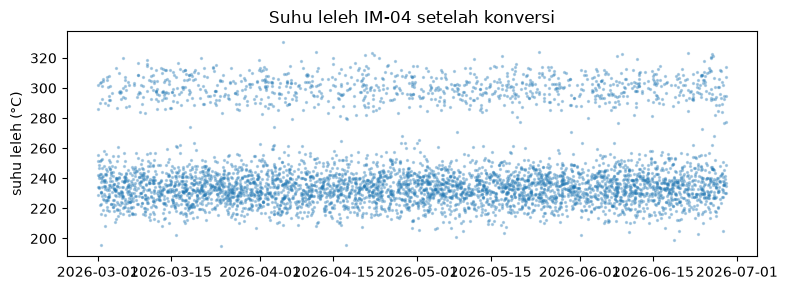

In [19]:
fig, ax = plt.subplots(figsize=(8, 3))
bagian = df[df["mesin"] == "IM-04"]
ax.scatter(bagian["waktu_produksi"], bagian["suhu_leleh_C"], s=2, alpha=0.3)
ax.set_title("Suhu leleh IM-04 setelah konversi")
ax.set_ylabel("suhu leleh (°C)")
plt.tight_layout()
plt.show()

Setelah dikonversi, lonjakan di bulan April sudah hilang. Suhu leleh IM-04 kini berada di dua kelompok yang sama
dengan mesin lain, yaitu sekitar 230 sampai 240 °C untuk PP dan ABS, serta sekitar 300 °C untuk PC.

### 3.4 Mengubah nilai yang mustahil menjadi `NaN`
Ada dua jenis nilai yang tidak mungkin terjadi. Tekanan injeksi 0 bar berarti sensor gagal membaca, karena plastik
tidak bisa disuntikkan tanpa tekanan. Waktu siklus −1 detik adalah kode dari sistem yang berarti datanya tidak ada.

Selain memeriksa setiap kolom secara terpisah, saya juga memeriksa logika antarkolom. Waktu pendinginan adalah bagian
dari satu siklus, sehingga tidak mungkin lebih lama daripada waktu siklus itu sendiri.

In [20]:
print("Sebelum: pendinginan >= siklus:", (df["waktu_pendinginan_s"] >= df["waktu_siklus_s"]).sum(), "baris")

tekanan_nol = df["tekanan_injeksi_bar"] <= 0
siklus_negatif = df["waktu_siklus_s"] <= 0
df.loc[tekanan_nol, "tekanan_injeksi_bar"] = np.nan
df.loc[siklus_negatif, "waktu_siklus_s"] = np.nan

catat("`tekanan_injeksi_bar` = 0", tekanan_nol.sum(), "Diubah menjadi NaN dan diisi median di pipeline",
      "Mustahil secara fisik karena sensor gagal membaca, sedangkan kolom lain di baris itu masih benar")
catat("`waktu_siklus_s` = −1", siklus_negatif.sum(), "Diubah menjadi NaN dan diisi median di pipeline",
      "Kode dari sistem untuk data yang tidak ada")

print(f"tekanan 0 → NaN: {tekanan_nol.sum()} | siklus −1 → NaN: {siklus_negatif.sum()}")
print("Sesudah: pendinginan >= siklus:", (df["waktu_pendinginan_s"] >= df["waktu_siklus_s"]).sum(), "baris")

Sebelum: pendinginan >= siklus: 75 baris
tekanan 0 → NaN: 125 | siklus −1 → NaN: 75
Sesudah: pendinginan >= siklus: 0 baris


Sebelum dibersihkan ada 75 baris dengan waktu pendinginan yang lebih lama daripada waktu siklus. Setelah waktu siklus
−1 diubah menjadi `NaN`, jumlahnya menjadi 0. Artinya semua baris tersebut adalah baris dengan waktu siklus −1,
sehingga masalah ini sudah ikut tertangani tanpa langkah tambahan.

In [21]:
# ✅ Cek 3.4
assert (df["tekanan_injeksi_bar"] <= 0).sum() == 0, "Masih ada tekanan 0."
assert (df["waktu_siklus_s"] <= 0).sum() == 0, "Masih ada waktu siklus negatif."
assert (df["waktu_pendinginan_s"] >= df["waktu_siklus_s"]).sum() == 0, "Masih ada pendinginan >= siklus."
assert len(df) == 25_000, "Jumlah baris berubah. Ubah menjadi NaN, jangan hapus barisnya."
print("✅ 3.4 beres")

✅ 3.4 beres


### 3.5 Memeriksa nilai ekstrem yang tersisa
Untuk nilai ekstrem yang tersisa, saya memakai aturan IQR per bahan. Sebuah nilai dianggap ekstrem jika berada di
bawah Q1 − 1,5 × IQR atau di atas Q3 + 1,5 × IQR. Setelah itu saya membandingkan persentase cacat pada baris yang
ekstrem dengan baris yang normal. Jika baris yang ekstrem jauh lebih sering cacat, berarti nilai tersebut adalah
informasi penting bagi model, bukan data yang rusak.

In [22]:
KOLOM_ANGKA = ["suhu_leleh_C", "suhu_cetakan_C", "tekanan_injeksi_bar", "kecepatan_injeksi_mm_s",
               "waktu_pendinginan_s", "waktu_siklus_s", "kelembaban_bahan_pct"]

baris = []
ada_ekstrem = pd.Series(False, index=df.index)   # baris yang ekstrem di minimal satu kolom
for kolom in KOLOM_ANGKA:
    g = df.groupby("bahan")[kolom]
    q1, q3 = g.transform("quantile", 0.25), g.transform("quantile", 0.75)
    iqr = q3 - q1
    ekstrem = (df[kolom] < q1 - 1.5 * iqr) | (df[kolom] > q3 + 1.5 * iqr)
    ada_ekstrem |= ekstrem
    baris.append({"kolom": kolom, "baris ekstrem": int(ekstrem.sum()),
                  "% cacat (ekstrem)": round(df.loc[ekstrem, TARGET].mean() * 100, 1),
                  "% cacat (normal)": round(df.loc[~ekstrem, TARGET].mean() * 100, 1)})
tabel_ekstrem = pd.DataFrame(baris).set_index("kolom")
tabel_ekstrem

,baris ekstrem,% cacat (ekstrem),% cacat (normal)
kolom,,,
suhu_leleh_C,169,34.9,7.6
suhu_cetakan_C,203,21.2,7.7
tekanan_injeksi_bar,184,22.8,7.6
kecepatan_injeksi_mm_s,178,10.1,7.7
waktu_pendinginan_s,181,22.7,7.7
waktu_siklus_s,145,20.0,7.7
kelembaban_bahan_pct,784,35.1,6.9


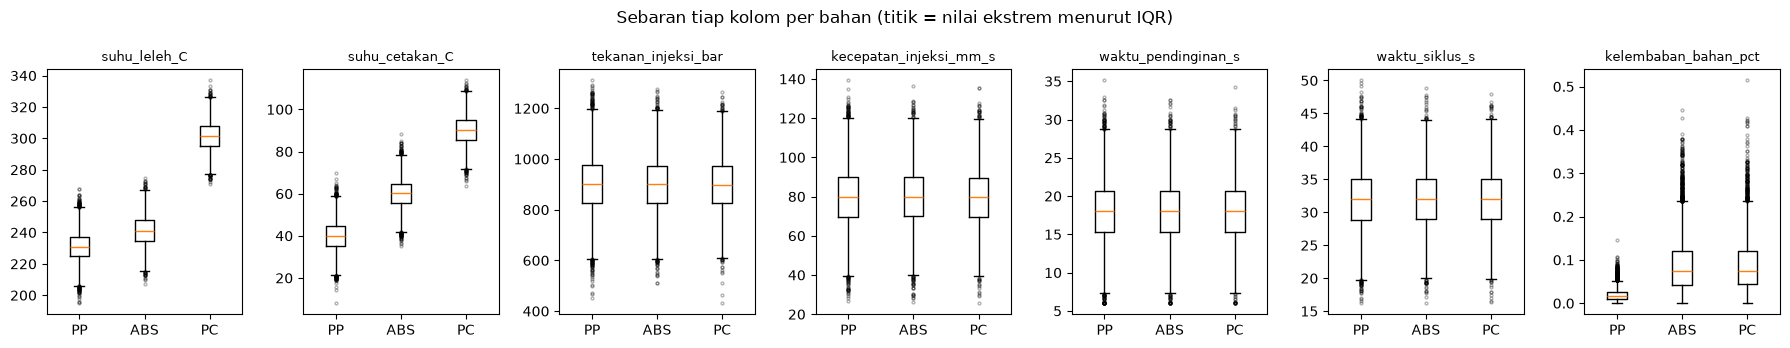

In [23]:
fig, axes = plt.subplots(1, len(KOLOM_ANGKA), figsize=(18, 3.5))
for ax, kolom in zip(axes, KOLOM_ANGKA):
    data = [df.loc[df["bahan"] == b, kolom].dropna() for b in SUHU_STANDAR]
    ax.boxplot(data, tick_labels=list(SUHU_STANDAR), flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(kolom, fontsize=9)
fig.suptitle("Sebaran tiap kolom per bahan (titik = nilai ekstrem menurut IQR)")
plt.tight_layout()
plt.show()

In [24]:
print(f"Baris dengan nilai ekstrem di minimal satu kolom: {ada_ekstrem.sum():,}")
print(f"% cacat baris ekstrem: {df.loc[ada_ekstrem, TARGET].mean():.1%} | baris normal: {df.loc[~ada_ekstrem, TARGET].mean():.1%}")
catat("Nilai ekstrem (IQR per bahan) di minimal satu kolom proses", ada_ekstrem.sum(), "Dibiarkan",
      "Baris ekstrem jauh lebih sering cacat, jadi nilainya adalah sinyal dan bukan data rusak")

Baris dengan nilai ekstrem di minimal satu kolom: 1,725
% cacat baris ekstrem: 27.0% | baris normal: 6.3%


Di semua kolom, baris yang ekstrem lebih sering cacat daripada baris yang normal. Pada suhu leleh dan kelembaban bahan,
persentase cacatnya bahkan sekitar empat sampai lima kali lipat. Secara keseluruhan, baris yang memiliki nilai ekstrem
di minimal satu kolom cacat sekitar 27%, sedangkan baris normal hanya sekitar 6%. Jika baris ini dibuang, model akan
kehilangan contoh yang paling penting untuk dipelajari. Karena itu semua nilai ekstrem saya biarkan.

Ada dua nilai yang awalnya terlihat mencurigakan, tetapi tetap saya biarkan. Kelembaban 0% hanya muncul pada PP, dan
nilai ini masih wajar karena PP hampir tidak menyerap air, sehingga kadarnya bisa menjadi 0,000 setelah dibulatkan.
Suhu cetakan sekitar 8 °C pada PP memang sangat dingin, tetapi cetakan bisa didinginkan dengan *chiller*, sehingga
nilai ini jarang terjadi tetapi tidak mustahil.

### 3.6 Memeriksa kecocokan shift dengan jam produksi
Jika setiap shift memiliki jam kerja yang tetap, jam pada `waktu_produksi` seharusnya mengelompok sesuai shift-nya.
Misalnya, siklus dengan label shift pagi seharusnya terjadi pada jam pagi.

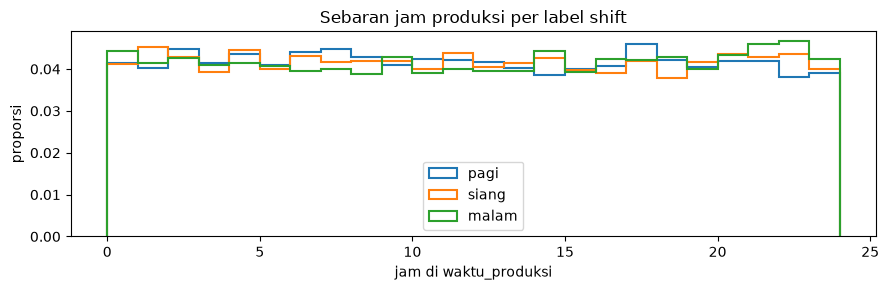

% cacat per label shift: {'malam': 10.0, 'pagi': 7.0, 'siang': 7.0}
% cacat per 8 jam      : {'00-08': 7.6, '08-16': 7.7, '16-24': 7.9}


In [25]:
jam = df["waktu_produksi"].dt.hour
fig, ax = plt.subplots(figsize=(9, 3))
for s in ["pagi", "siang", "malam"]:
    ax.hist(jam[df["shift"] == s], bins=24, range=(0, 24), histtype="step", linewidth=1.5, label=s, density=True)
ax.set_xlabel("jam di waktu_produksi"); ax.set_ylabel("proporsi"); ax.legend()
ax.set_title("Sebaran jam produksi per label shift")
plt.tight_layout()
plt.show()

print("% cacat per label shift:", (df.groupby("shift")[TARGET].mean() * 100).round(1).to_dict())
print("% cacat per 8 jam      :", (df.groupby(jam // 8)[TARGET].mean() * 100).round(1)
      .rename({0: "00-08", 1: "08-16", 2: "16-24"}).to_dict())

Ketiga label shift ternyata tersebar merata di semua jam. Artinya label `shift` tidak cocok dengan jam di
`waktu_produksi`, sehingga salah satu dari kedua kolom itu tidak bisa dipercaya. Menariknya, persentase cacat berbeda
menurut label shift, yaitu sekitar 10% pada shift malam dan 7% pada shift lainnya, tetapi tidak berbeda menurut jam
produksi.

Saya tidak bisa memastikan kolom mana yang benar tanpa bertanya kepada klien. Karena itu saya membiarkan datanya apa
adanya dan mencatat masalah ini sebagai pertanyaan untuk klien. Saya juga tidak menjadikan `shift` sebagai
masukan aplikasi. Selain keandalannya diragukan, aplikasi hanya meminta bahan, mesin, dan parameter proses sebagai masukan
dari operator.

In [26]:
catat("Label `shift` tidak cocok dengan jam di `waktu_produksi`", len(df),
      "Dibiarkan, tidak dipakai sebagai masukan, dan ditanyakan ke klien",
      "Ketiga shift tersebar merata di semua jam, jadi salah satu kolom tidak andal")
print("✅ 3.6 dicatat")

✅ 3.6 dicatat


### 3.7 Nilai kosong setelah dibersihkan
Nilai kosong saya hitung di akhir, karena langkah 3.4 menambah `NaN` yang baru.

In [27]:
kosong_akhir = df[KOLOM_ANGKA].isna().sum()
kosong_akhir = kosong_akhir[kosong_akhir > 0]
print(kosong_akhir.to_string())

for kolom in ["kelembaban_bahan_pct", "waktu_pendinginan_s"]:
    catat(f"`{kolom}` kosong", df[kolom].isna().sum(),
          "Dibiarkan NaN dan diisi median data train di pipeline",
          "Median dihitung dari data train saja supaya tidak ada kebocoran data")

tekanan_injeksi_bar      125
waktu_pendinginan_s      250
waktu_siklus_s            75
kelembaban_bahan_pct    1000


Jumlah kolom yang memiliki nilai kosong bertambah dari dua menjadi empat, yaitu tekanan injeksi, waktu siklus, waktu
pendinginan, dan kelembaban bahan. Semuanya belum saya isi, karena pengisiannya dilakukan di dalam pipeline dengan
median dari data train. Ada satu hal yang perlu saya perhatikan nanti. Kelembaban PP jauh lebih rendah daripada ABS dan
PC, sehingga satu median untuk semua bahan kurang tepat untuk kolom ini. Pilihan cara pengisiannya akan saya bahas di
bagian 7.

In [28]:
# ✅ Cek 3.7
assert kosong_akhir["tekanan_injeksi_bar"] == CATATAN["`tekanan_injeksi_bar` = 0"]["Jumlah baris"]
assert kosong_akhir["waktu_siklus_s"] == CATATAN["`waktu_siklus_s` = −1"]["Jumlah baris"]
assert df[["mesin", "bahan", "shift", TARGET]].isna().sum().sum() == 0, "Kolom kategori dan target tidak boleh kosong."
print("✅ 3.7 beres")

✅ 3.7 beres


### 3.8 Tabel masalah data
Tabel ini merangkum semua masalah yang saya temukan beserta cara penanganannya.

In [29]:
tabel_masalah = pd.DataFrame(CATATAN).T.rename_axis("Masalah")
tabel_masalah

,Jumlah baris,Penanganan,Alasan
Masalah,,,
"Penulisan `bahan` tidak seragam (`PP `, `P.P`, `pp`, `Abs`, …)",761,"Dirapikan menjadi PP, ABS, atau PC","Salah ketik, isinya jelas"
"Penulisan `shift` tidak seragam (`SIANG`, `malam `, `Pagi`)",506,Diubah ke huruf kecil dan spasi dihapus,"Salah ketik, isinya jelas"
Baris duplikat persis,350,Dihapus dengan `drop_duplicates`,Satu siklus tercatat dua kali dan harus dibuan...
`suhu_leleh_C` IM-04 tercatat dalam °F (2026-04-10 s.d. 2026-04-23),579,Dikonversi ke °C dengan (°F − 32) × 5/9 untuk ...,"Setelah dikonversi, rata-rata tiap bahan kemba..."
`tekanan_injeksi_bar` = 0,125,Diubah menjadi NaN dan diisi median di pipeline,Mustahil secara fisik karena sensor gagal memb...
`waktu_siklus_s` = −1,75,Diubah menjadi NaN dan diisi median di pipeline,Kode dari sistem untuk data yang tidak ada
Nilai ekstrem (IQR per bahan) di minimal satu kolom proses,1725,Dibiarkan,"Baris ekstrem jauh lebih sering cacat, jadi ni..."
Label `shift` tidak cocok dengan jam di `waktu_produksi`,25000,"Dibiarkan, tidak dipakai sebagai masukan, dan ...","Ketiga shift tersebar merata di semua jam, jad..."
`kelembaban_bahan_pct` kosong,1000,Dibiarkan NaN dan diisi median data train di p...,Median dihitung dari data train saja supaya ti...


### 3.9 Menyimpan data bersih
Data yang sudah dibersihkan saya simpan ke `data/bersih.csv`, sehingga bagian berikutnya bisa langsung memakai data
ini. File `data/raw.csv` tidak saya ubah sama sekali.

In [30]:
PATH_BERSIH = ROOT / "data" / "bersih.csv"
df.to_csv(PATH_BERSIH, index=False)
print(f"Tersimpan: data/bersih.csv ({len(df):,} baris, {df.shape[1]} kolom)")

Tersimpan: data/bersih.csv (25,000 baris, 12 kolom)


In [31]:
# ✅ Cek akhir bagian 3
cek = pd.read_csv(PATH_BERSIH, parse_dates=["waktu_produksi"])
assert len(cek) == 25_000 and cek.duplicated().sum() == 0
assert cek["suhu_leleh_C"].max() < 400
assert set(cek["bahan"]) == {"PP", "ABS", "PC"}
print(f"✅ Bagian 3 beres. Data bersih: {len(cek):,} baris, cacat {cek[TARGET].mean():.1%}")

✅ Bagian 3 beres. Data bersih: 25,000 baris, cacat 7.8%


### Ringkasan bagian 3

- Data mentah 25.350 baris menjadi 25.000 baris setelah 350 duplikat dihapus. Proporsi cacat 7,8%.
- Suhu leleh IM-04 pada 10–23 April tercatat dalam °F (579 baris). Setelah dikonversi, rata-rata tiap bahan kembali
  sesuai standar, jadi nilainya benar dan hanya satuannya yang salah.
- Tekanan 0 bar dan waktu siklus −1 detik diubah menjadi `NaN`. Semua nilai kosong diisi nanti di *pipeline* dengan
  median dari data train.
- Nilai ekstrem dibiarkan, karena baris ekstrem cacat sekitar 27%, sedangkan baris normal sekitar 6%.
- Label `shift` tidak cocok dengan jam produksi, sehingga tidak dipakai sebagai masukan dan ditanyakan ke klien.

## 4 · EDA terhadap target (cacat)

Di bagian 3 saya memastikan datanya benar. Di bagian ini saya mencari jawaban atas pertanyaan utama klien: **dalam
kondisi seperti apa sebuah komponen cenderung cacat?** Jawabannya menentukan fitur yang saya buat di bagian 5.

Ada tiga dugaan yang saya uji, ditambah pemeriksaan parameter proses lainnya:

1. Cacat berhubungan dengan **selisih** suhu dari standar bahan, dan bentuk hubungannya seperti huruf U.
2. Kelembaban hanya berpengaruh pada bahan yang menyerap air, yaitu ABS dan PC.
3. IM-03 lebih sering menghasilkan komponen cacat dibandingkan mesin lain.

Semua grafik di bagian ini dibuat dengan cara yang sama. Nilai sebuah kolom dikelompokkan, lalu saya hitung persentase
cacat di setiap kelompok. Garis putus-putus abu-abu menunjukkan rata-rata cacat keseluruhan, yaitu sekitar 7,8%.
Kelompok dengan kurang dari 30 baris tidak saya tampilkan, karena persentase dari sedikit baris mudah melonjak secara
kebetulan.

Kolom bantu seperti selisih suhu saya buat di salinan `eda`, bukan di `df`. Fitur resmi untuk model baru dibuat di
`src/features.py` pada bagian 5, supaya saat pelatihan dan saat prediksi di aplikasi dipakai kode yang sama.

In [32]:
df = pd.read_csv(PATH_BERSIH, parse_dates=["waktu_produksi"])
RATA_CACAT = df[TARGET].mean()

eda = df.copy()
eda["selisih_leleh"] = eda["suhu_leleh_C"] - eda["bahan"].map({b: s[0] for b, s in SUHU_STANDAR.items()})
eda["selisih_cetakan"] = eda["suhu_cetakan_C"] - eda["bahan"].map({b: s[1] for b, s in SUHU_STANDAR.items()})


def persen_cacat(data, grup, minimal=30):
    # % cacat dan jumlah baris per grup. Grup dengan baris < minimal dibuang supaya tidak menyesatkan.
    hasil = data.groupby(grup, observed=True)[TARGET].agg(persen="mean", n="size")
    hasil["persen"] *= 100
    return hasil[hasil["n"] >= minimal]


def garis_rata(ax):
    ax.axhline(RATA_CACAT * 100, color="grey", linestyle="--", linewidth=0.8)


print(f"Data bersih: {len(df):,} baris | rata-rata cacat {RATA_CACAT:.1%}")

Data bersih: 25,000 baris | rata-rata cacat 7.8%


### 4.1 Cacat per bahan dan per mesin
Saya mulai dari pembagian yang paling sederhana, yaitu jenis bahan dan mesin.

In [33]:
print("% cacat per bahan:")
print(persen_cacat(df, "bahan").round(1).to_string(), "\n")
print("% cacat per mesin:")
print(persen_cacat(df, "mesin").round(1).to_string(), "\n")

print("Komposisi bahan di setiap mesin (% baris):")
print((pd.crosstab(df["mesin"], df["bahan"], normalize="index") * 100).round(0).to_string(), "\n")

print("% cacat per mesin × bahan:")
pd.crosstab(df["mesin"], df["bahan"], values=df[TARGET], aggfunc="mean").mul(100).round(1)

% cacat per bahan:
       persen      n
bahan               
ABS      11.8   7522
PC       11.7   5053
PP        3.7  12425 

% cacat per mesin:
       persen     n
mesin              
IM-01     6.4  7491
IM-02     6.6  7468
IM-03    12.6  5004
IM-04     6.6  5037 

Komposisi bahan di setiap mesin (% baris):
bahan   ABS    PC    PP
mesin                  
IM-01  31.0  20.0  49.0
IM-02  30.0  20.0  49.0
IM-03  30.0  21.0  49.0
IM-04  29.0  19.0  52.0 

% cacat per mesin × bahan:


bahan,ABS,PC,PP
mesin,,,
IM-01,10.7,9.3,2.5
IM-02,9.5,10.9,3.1
IM-03,18.1,16.8,7.5
IM-04,10.7,11.1,2.6


Ada dua pola yang jelas.

- **ABS dan PC sekitar tiga kali lebih sering cacat daripada PP** (sekitar 12% dibanding 4%). Penyebabnya saya cari di
  bagian 4.3.
- **IM-03 hampir dua kali lebih sering cacat daripada tiga mesin lain** (sekitar 12,6% dibanding 6,5%). Penyebabnya
  bukan karena IM-03 lebih banyak mencetak ABS atau PC, karena komposisi bahan di keempat mesin hampir sama. Di tabel
  terakhir juga terlihat bahwa IM-03 paling sering cacat untuk **setiap** bahan. Penyebabnya saya telusuri di
  bagian 4.5.

### 4.2 Selisih suhu dari standar bahan
Dugaan saya, hubungan antara suhu dan cacat berbentuk huruf U. Jika suhu leleh terlalu rendah, plastik terlalu kental
sehingga cetakan tidak terisi penuh. Jika terlalu tinggi, plastik bisa rusak karena panas atau meluber keluar dari
celah cetakan. Hal yang sama berlaku untuk suhu cetakan. Jika cetakan terlalu dingin, plastik membeku sebelum cetakan
penuh. Jika terlalu panas, komponen mudah melengkung.

Karena suhu standar setiap bahan berbeda, yang saya bandingkan adalah **selisih** suhu dari standar bahannya, bukan
suhu mentahnya. Suhu leleh 300 °C normal untuk PC, tetapi terlalu tinggi 70 °C untuk PP.

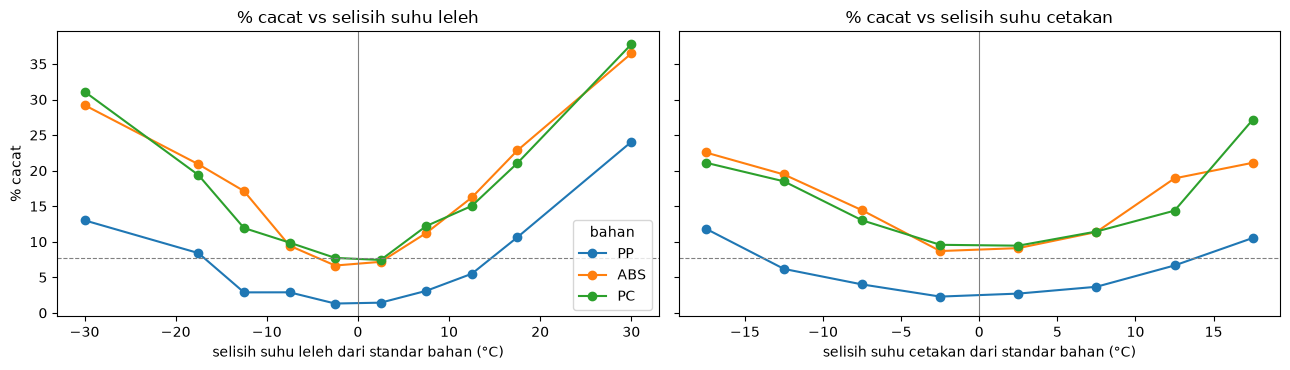

% cacat per kelompok selisih suhu leleh (semua bahan):


selisih_leleh,"(-40, -20]","(-20, -15]","(-15, -10]","(-10, -5]","(-5, 0]","(0, 5]","(5, 10]","(10, 15]","(15, 20]","(20, 40]"
persen,21.1,14.2,8.9,6.2,4.2,4.4,7.4,10.7,16.5,30.8
n,280.0,675.0,1901.0,3522.0,4917.0,5212.0,4216.0,2488.0,1189.0,600.0


In [34]:
BATAS_SELISIH = [-40, -20, -15, -10, -5, 0, 5, 10, 15, 20, 40]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, kolom, nama in zip(axes, ["selisih_leleh", "selisih_cetakan"], ["suhu leleh", "suhu cetakan"]):
    kelompok = pd.cut(eda[kolom], BATAS_SELISIH)
    for b in SUHU_STANDAR:
        bagian = eda["bahan"] == b
        hasil = persen_cacat(eda[bagian], kelompok[bagian])
        ax.plot([iv.mid for iv in hasil.index], hasil["persen"], marker="o", label=b)
    ax.axvline(0, color="grey", linewidth=0.8)
    garis_rata(ax)
    ax.set_xlabel(f"selisih {nama} dari standar bahan (°C)")
    ax.set_title(f"% cacat vs selisih {nama}")
axes[0].set_ylabel("% cacat")
axes[0].legend(title="bahan")
plt.tight_layout()
plt.show()

print("% cacat per kelompok selisih suhu leleh (semua bahan):")
persen_cacat(eda, pd.cut(eda["selisih_leleh"], BATAS_SELISIH)).round(1).T

Dugaan bentuk U terbukti, untuk suhu leleh maupun suhu cetakan dan untuk ketiga bahan. Persentase cacat paling rendah
ketika suhu berada dalam ±5 °C dari standar, yaitu sekitar 4%. Semakin jauh dari standar, ke arah lebih dingin maupun
lebih panas, persentase cacatnya naik. Pada selisih suhu leleh lebih dari 20 °C, persentase cacat sudah sekitar 31%.

Pola ini penting untuk pemodelan. Regresi logistik hanya bisa mempelajari hubungan "makin besar nilainya, makin
besar (atau makin kecil) peluang cacat". Model ini tidak bisa menangkap bentuk U dari suhu mentah. Korelasi biasa juga
tidak bisa melihatnya, seperti yang terlihat di sel berikut.

In [35]:
pembanding = pd.DataFrame({
    "suhu leleh mentah": eda["suhu_leleh_C"],
    "selisih dari standar": eda["selisih_leleh"],
    "|selisih| dari standar": eda["selisih_leleh"].abs(),
})
print("Korelasi dengan cacat:")
print(pembanding.corrwith(eda[TARGET]).round(3).to_string())

Korelasi dengan cacat:
suhu leleh mentah         0.112
selisih dari standar      0.072
|selisih| dari standar    0.183


Korelasi selisih suhu biasa dengan cacat hanya sekitar 0,07, karena pengaruh sisi "terlalu dingin" dan sisi "terlalu
panas" saling meniadakan. Setelah diambil nilai mutlaknya (seberapa jauh dari standar, tanpa memedulikan arah),
korelasinya naik menjadi sekitar 0,18. Korelasi suhu mentah (sekitar 0,11) sebagian besar hanya mencerminkan bahwa
ABS dan PC, yang suhunya lebih tinggi, memang lebih sering cacat.

**Implikasi untuk bagian 5:** saya akan membuat fitur selisih suhu leleh dan selisih suhu cetakan dari standar bahan,
beserta nilai mutlaknya.

### 4.3 Kelembaban bahan, dipisah per bahan
ABS dan PC menyerap air dari udara, sehingga harus dikeringkan dulu sebelum dicetak. Jika masih basah, air di dalamnya
berubah menjadi uap saat dilelehkan dan menimbulkan gelembung atau garis-garis perak di permukaan komponen. PP hampir
tidak menyerap air, jadi seharusnya tidak terpengaruh.

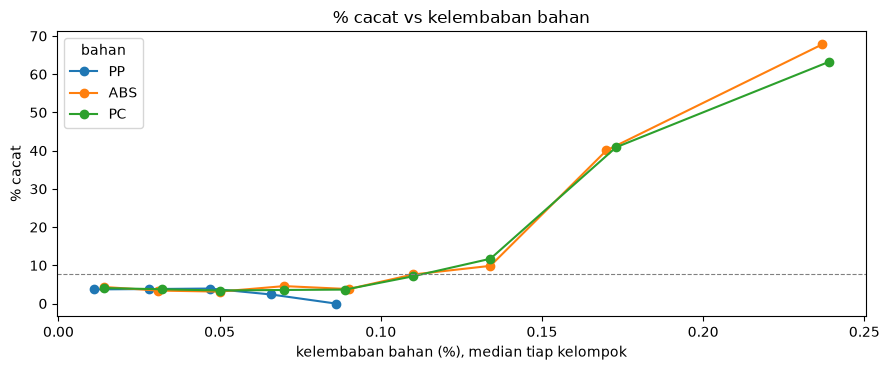

% cacat per kelompok kelembaban (kosong = kelompok < 30 baris):
bahan                  ABS    PC   PP
kelembaban_bahan_pct                 
(-0.001, 0.02]         4.3   4.0  3.7
(0.02, 0.04]           3.4   3.7  3.8
(0.04, 0.06]           3.1   3.4  3.9
(0.06, 0.08]           4.6   3.6  2.4
(0.08, 0.1]            3.8   3.7  0.0
(0.1, 0.12]            7.6   7.1  NaN
(0.12, 0.15]           9.9  11.7  NaN
(0.15, 0.2]           40.1  40.9  NaN
(0.2, 0.6]            67.8  63.2  NaN

% cacat pada baris yang kelembabannya kosong: 7.6%


In [36]:
BATAS_LEMBAB = [0, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20, 0.60]
kelompok = pd.cut(eda["kelembaban_bahan_pct"], BATAS_LEMBAB, include_lowest=True)

fig, ax = plt.subplots(figsize=(9, 3.8))
for b in SUHU_STANDAR:
    bagian = eda["bahan"] == b
    hasil = persen_cacat(eda[bagian], kelompok[bagian])
    # posisi titik = median kelembaban di dalam kelompok, supaya kelompok terakhir yang lebar tidak meregangkan sumbu
    posisi = eda[bagian].groupby(kelompok[bagian], observed=True)["kelembaban_bahan_pct"].median()
    ax.plot(posisi.loc[hasil.index], hasil["persen"], marker="o", label=b)
garis_rata(ax)
ax.set_xlabel("kelembaban bahan (%), median tiap kelompok")
ax.set_ylabel("% cacat")
ax.set_title("% cacat vs kelembaban bahan")
ax.legend(title="bahan")
plt.tight_layout()
plt.show()

print("% cacat per kelompok kelembaban (kosong = kelompok < 30 baris):")
print(pd.crosstab(kelompok, eda["bahan"], values=eda[TARGET], aggfunc="mean")
      .mul(100).round(1).where(pd.crosstab(kelompok, eda["bahan"]) >= 30).to_string())
print(f"\n% cacat pada baris yang kelembabannya kosong: {eda.loc[eda['kelembaban_bahan_pct'].isna(), TARGET].mean():.1%}")

Dugaan kedua juga terbukti, dan polanya berbentuk **ambang batas**, bukan garis lurus.

- Untuk ABS dan PC, persentase cacat tetap rendah (sekitar 3–4%) selama kelembaban di bawah sekitar 0,10%. Di atas
  0,10% mulai naik, lalu melonjak tajam di atas 0,15%. Pada kelembaban di atas 0,20%, sekitar dua dari tiga komponen
  cacat.
- Untuk PP, persentase cacat tetap datar di sekitar 3–4% berapa pun kelembabannya. Kelembaban PP juga hampir tidak
  pernah melewati 0,10%.

Ini menjelaskan temuan di bagian 4.1. ABS dan PC lebih sering cacat terutama karena sebagian bahannya masih terlalu
basah saat dicetak. Saat kelembabannya terkendali, persentase cacat ABS dan PC hampir sama dengan PP.

Baris yang kelembabannya kosong memiliki persentase cacat yang hampir sama dengan rata-rata. Artinya data kosong ini
tampak acak, dan tidak perlu dibuatkan fitur penanda "kosong".

**Implikasi untuk bagian 5 dan 7:**
- Saya membuat fitur kelembaban yang hanya berlaku untuk bahan higroskopis, yaitu kelembaban × (bahan ABS atau PC).
  Untuk PP, nilainya 0.
- Median kelembaban PP (sekitar 0,02%) jauh lebih rendah daripada ABS dan PC (sekitar 0,08%). Karena itu mengisi
  kelembaban yang kosong dengan median per bahan mungkin lebih tepat. Dugaan ini saya uji di bagian 7.3.

### 4.4 Parameter proses lainnya
Selanjutnya tekanan injeksi, kecepatan injeksi, waktu pendinginan, dan waktu siklus. Keempat kolom ini tidak memiliki
standar per bahan (mediannya sama untuk ketiga bahan), jadi saya membaginya menjadi 10 kelompok dengan jumlah baris
yang sama (desil).

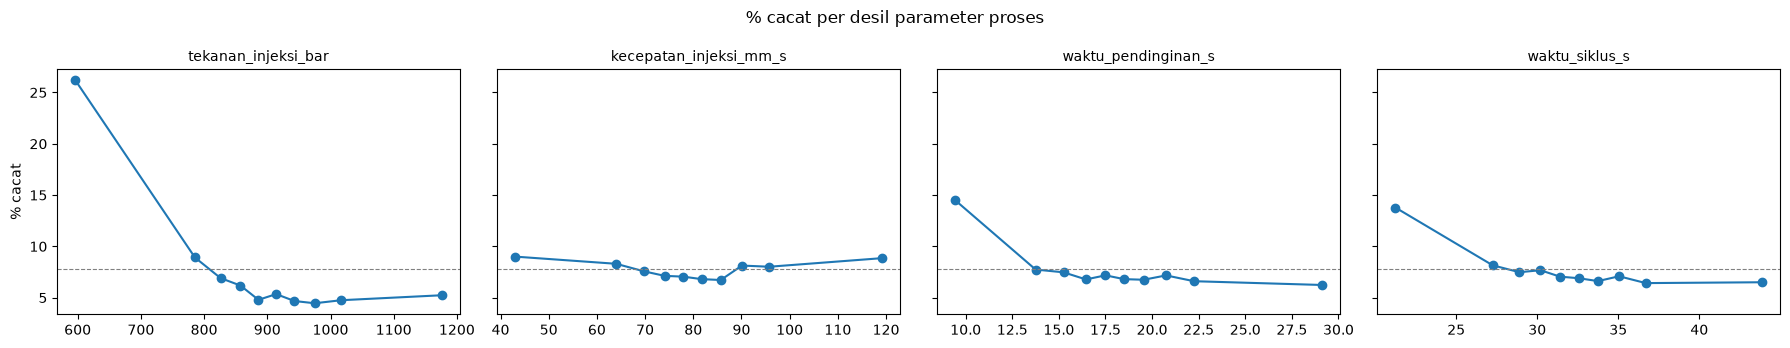

Median per bahan:
       tekanan_injeksi_bar  kecepatan_injeksi_mm_s  waktu_pendinginan_s  waktu_siklus_s
bahan                                                                                  
ABS                  901.0                    79.8                 18.1            32.0
PC                   899.0                    80.0                 18.1            32.0
PP                   900.0                    79.8                 18.0            32.0


In [37]:
KOLOM_LAIN = ["tekanan_injeksi_bar", "kecepatan_injeksi_mm_s", "waktu_pendinginan_s", "waktu_siklus_s"]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5), sharey=True)
for ax, kolom in zip(axes, KOLOM_LAIN):
    hasil = persen_cacat(eda, pd.qcut(eda[kolom], 10))
    ax.plot([iv.mid for iv in hasil.index], hasil["persen"], marker="o")
    garis_rata(ax)
    ax.set_title(kolom, fontsize=10)
axes[0].set_ylabel("% cacat")
fig.suptitle("% cacat per desil parameter proses")
plt.tight_layout()
plt.show()

print("Median per bahan:")
print(eda.groupby("bahan")[KOLOM_LAIN].median().to_string())

In [38]:
print("Korelasi waktu pendinginan dengan waktu siklus:",
      round(eda["waktu_pendinginan_s"].corr(eda["waktu_siklus_s"]), 2))

sisa = eda["waktu_siklus_s"] - eda["waktu_pendinginan_s"]   # bagian siklus di luar pendinginan
print("\n% cacat per desil (waktu siklus − waktu pendinginan):")
print(persen_cacat(eda, pd.qcut(sisa, 10))["persen"].round(1).to_string())

Korelasi waktu pendinginan dengan waktu siklus: 0.89

% cacat per desil (waktu siklus − waktu pendinginan):
(5.499, 11.4]    8.1
(11.4, 12.3]     8.1
(12.3, 13.0]     7.5
(13.0, 13.5]     7.5
(13.5, 14.0]     7.8
(14.0, 14.5]     7.5
(14.5, 15.0]     7.6
(15.0, 15.7]     7.2
(15.7, 16.5]     8.4
(16.5, 22.7]     7.8


- **Tekanan injeksi** berpengaruh **satu arah**. Tekanan yang terlalu rendah (desil terbawah, di bawah sekitar 760 bar)
  membuat persentase cacat naik menjadi sekitar 26%, karena plastik tidak terdorong cukup kuat untuk memenuhi cetakan.
  Di atas sekitar 870 bar, persentase cacatnya datar. Tekanan tinggi tidak menambah cacat.
- **Waktu pendinginan** juga berpengaruh satu arah. Pendinginan yang terlalu singkat (di bawah sekitar 13 detik)
  membuat persentase cacat sekitar dua kali rata-rata. Komponen yang dikeluarkan saat masih lunak mudah berubah bentuk.
- **Waktu siklus** tampak berpola sama, tetapi korelasinya dengan waktu pendinginan sekitar 0,89. Ketika waktu
  pendinginan dikurangkan dari waktu siklus, sisanya tidak berpola sama sekali. Artinya, waktu siklus hanya "ikut-ikutan"
  karena di dalamnya ada waktu pendinginan, dan tidak memberi informasi tambahan.
- **Kecepatan injeksi** hampir tidak berpengaruh. Hanya ada lengkungan U yang sangat landai (sekitar 7% di tengah
  dan 9% di kedua ujung).

**Implikasi untuk model:** regresi logistik bisa menangkap pengaruh satu arah, tetapi bentuknya berupa "lutut" (datar
lalu naik tajam), bukan garis lurus. Model berbasis pohon seperti XGBoost bisa menangkap bentuk ini dengan sendirinya.
Untuk regresi logistik, saya bisa membantu dengan fitur seperti "seberapa jauh tekanan di bawah 850 bar". Waktu siklus
dan waktu pendinginan sangat berkorelasi, jadi pada regresi logistik koefisien keduanya perlu dibaca dengan hati-hati.

### 4.5 Mengapa IM-03 lebih sering cacat?
Ada dua kemungkinan penjelasan.

- **(a)** IM-03 dijalankan dengan pengaturan yang lebih buruk, misalnya suhunya lebih sering menyimpang dari standar.
  Jika ini penyebabnya, mesinnya sendiri sebenarnya normal.
- **(b)** Mesinnya sendiri bermasalah, sehingga dengan pengaturan yang sama pun IM-03 tetap lebih sering cacat.

Saya memeriksa keduanya.

In [39]:
KOLOM_PROSES = ["selisih_leleh", "selisih_cetakan", "tekanan_injeksi_bar", "kecepatan_injeksi_mm_s",
                "waktu_pendinginan_s", "kelembaban_bahan_pct"]
print("Rata-rata parameter per mesin:")
print(eda.groupby("mesin")[KOLOM_PROSES].mean().round(2).to_string(), "\n")

print("Rata-rata selisih suhu leleh IM-03 per bulan (°C):")
im03 = eda[eda["mesin"] == "IM-03"]
print(im03.groupby(im03["waktu_produksi"].dt.to_period("M"))["selisih_leleh"].mean().round(1).to_string())

Rata-rata parameter per mesin:
       selisih_leleh  selisih_cetakan  tekanan_injeksi_bar  kecepatan_injeksi_mm_s  waktu_pendinginan_s  kelembaban_bahan_pct
mesin                                                                                                                        
IM-01           0.14            -0.04               900.90                   79.87                18.03                  0.05
IM-02           0.03             0.04               900.25                   79.80                18.05                  0.05
IM-03           6.01             0.01               900.76                   79.91                17.99                  0.06
IM-04          -0.04             0.06               901.07                   79.94                18.03                  0.05 

Rata-rata selisih suhu leleh IM-03 per bulan (°C):
waktu_produksi
2026-03    6.1
2026-04    6.1
2026-05    6.0
2026-06    5.9
Freq: M


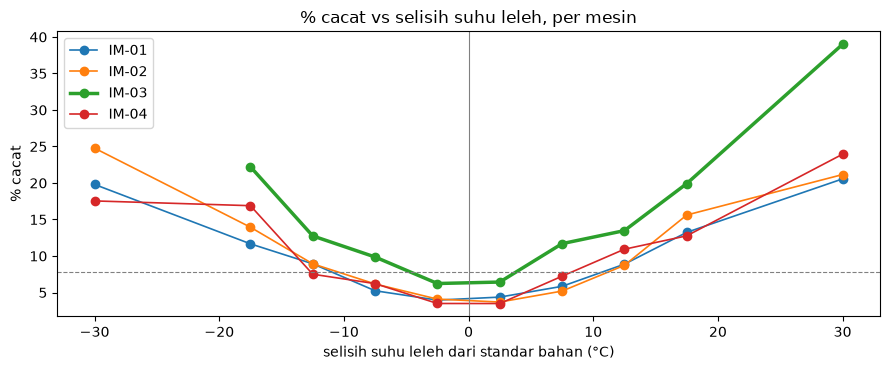

% cacat ketika suhu leleh dalam ±5 °C dari standar:
       persen     n
mesin              
IM-01     4.2  3096
IM-02     3.8  3050
IM-03     6.4  1730
IM-04     3.5  2159


In [40]:
fig, ax = plt.subplots(figsize=(9, 3.8))
kelompok = pd.cut(eda["selisih_leleh"], BATAS_SELISIH)
for mesin in sorted(eda["mesin"].unique()):
    bagian = eda["mesin"] == mesin
    hasil = persen_cacat(eda[bagian], kelompok[bagian])
    ax.plot([iv.mid for iv in hasil.index], hasil["persen"], marker="o", label=mesin,
            linewidth=2.5 if mesin == "IM-03" else 1.2)
ax.axvline(0, color="grey", linewidth=0.8)
garis_rata(ax)
ax.set_xlabel("selisih suhu leleh dari standar bahan (°C)")
ax.set_ylabel("% cacat")
ax.set_title("% cacat vs selisih suhu leleh, per mesin")
ax.legend()
plt.tight_layout()
plt.show()

dekat_standar = eda["selisih_leleh"].abs() < 5
print("% cacat ketika suhu leleh dalam ±5 °C dari standar:")
print(persen_cacat(eda[dekat_standar], "mesin").round(1).to_string())

Ternyata **kedua penjelasan sama-sama benar.**

- **(a) IM-03 berjalan sekitar 6 °C lebih panas.** Rata-rata selisih suhu leleh IM-03 sekitar +6 °C, sedangkan
  tiga mesin lain sekitar 0 °C. Parameter lain di IM-03 tidak berbeda. Selisih ini konsisten dari Maret sampai Juni,
  jadi bukan kerusakan sesaat. Kemungkinan *setting* pemanas IM-03 memang lebih tinggi. Akibatnya, IM-03 lebih sering
  berada di sisi kanan kurva U, tempat persentase cacat lebih tinggi.
- **(b) Pada selisih suhu yang sama pun, IM-03 tetap lebih sering cacat.** Ketika suhu leleh berada dalam ±5 °C
  dari standar, IM-03 masih cacat sekitar 6%, sedangkan mesin lain sekitar 4%. Garis IM-03 di grafik berada di atas
  mesin lain hampir di sepanjang sumbu. Jadi ada faktor lain di mesin ini yang tidak tercatat di data, misalnya
  komponen mesin yang aus.

Ada satu hal lagi yang bisa disimpulkan dari grafik. Titik terendah kurva IM-03 tetap berada di sekitar selisih 0 °C,
sama seperti mesin lain. Seandainya sensor IM-03 salah baca dan selalu menunjukkan angka 6 °C terlalu tinggi, titik
terendahnya akan bergeser ke sekitar +6 °C. Karena tidak bergeser, kemungkinan besar sensornya benar dan IM-03 memang
dijalankan lebih panas.

**Implikasi:**
- `mesin` harus menjadi masukan model, karena sebagian pengaruh IM-03 tidak bisa dijelaskan oleh parameter proses.
- Saran untuk klien: periksa *setting* suhu IM-03 dan turunkan sekitar 6 °C, lalu periksa kondisi fisik mesinnya.

### 4.6 Hubungan antarparameter
Saya juga memeriksa korelasi antarparameter. Dua kolom yang sangat berkorelasi membawa informasi yang hampir sama,
dan ini bisa membuat koefisien regresi logistik sulit ditafsirkan.

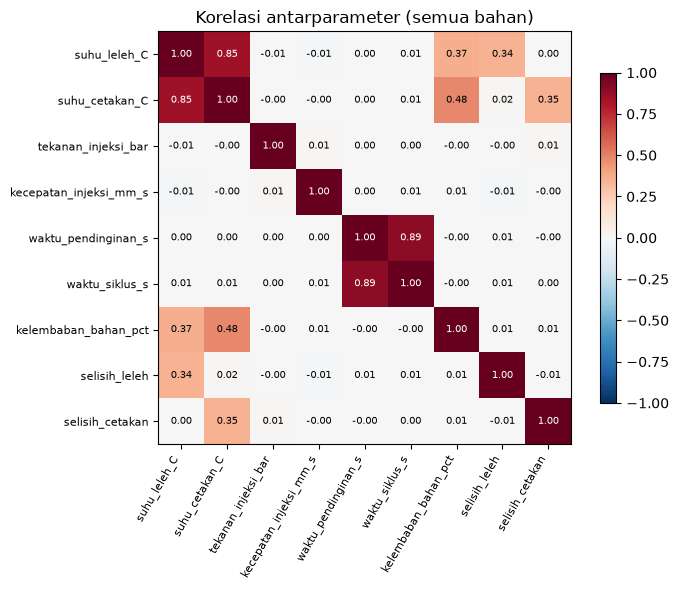

Korelasi suhu leleh dengan suhu cetakan:
  semua bahan digabung : 0.85
  di dalam PP          : -0.01
  di dalam ABS         : -0.01
  di dalam PC          : -0.00


In [41]:
KOLOM_KORELASI = KOLOM_ANGKA + ["selisih_leleh", "selisih_cetakan"]
korelasi = eda[KOLOM_KORELASI].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
gambar = ax.imshow(korelasi, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(KOLOM_KORELASI)), KOLOM_KORELASI, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(KOLOM_KORELASI)), KOLOM_KORELASI, fontsize=8)
for i in range(len(KOLOM_KORELASI)):
    for j in range(len(KOLOM_KORELASI)):
        ax.text(j, i, f"{korelasi.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(korelasi.iloc[i, j]) > 0.6 else "black")
fig.colorbar(gambar, ax=ax, shrink=0.8)
ax.set_title("Korelasi antarparameter (semua bahan)")
plt.tight_layout()
plt.show()

print("Korelasi suhu leleh dengan suhu cetakan:")
print(f"  semua bahan digabung : {eda['suhu_leleh_C'].corr(eda['suhu_cetakan_C']):.2f}")
for b in SUHU_STANDAR:
    bagian = eda[eda["bahan"] == b]
    print(f"  di dalam {b:<3}         : {bagian['suhu_leleh_C'].corr(bagian['suhu_cetakan_C']):.2f}")

Suhu leleh, suhu cetakan, dan kelembaban tampak saling berkorelasi kuat jika semua bahan digabung (suhu leleh dengan
suhu cetakan sekitar 0,85). Namun di dalam masing-masing bahan, korelasinya hampir 0. Korelasi tinggi tadi hanya
muncul karena PC dicetak pada suhu leleh dan suhu cetakan yang sama-sama tinggi, sedangkan PP pada keduanya rendah.
Selisih suhu dari standar juga tidak berkorelasi dengan parameter lain, kecuali dengan kolom suhu asalnya sendiri.
Ini alasan tambahan untuk memakai selisih suhu sebagai fitur.

Satu-satunya pasangan yang benar-benar berkorelasi adalah waktu pendinginan dan waktu siklus (sekitar 0,89), seperti
yang sudah dibahas di bagian 4.4.

### 4.7 Pola terhadap waktu
Terakhir, saya memeriksa apakah persentase cacat berubah dari waktu ke waktu. Jika ya, pembagian data secara acak di
bagian 6 bisa memberi gambaran yang terlalu optimis, karena model "melihat masa depan" saat dilatih.

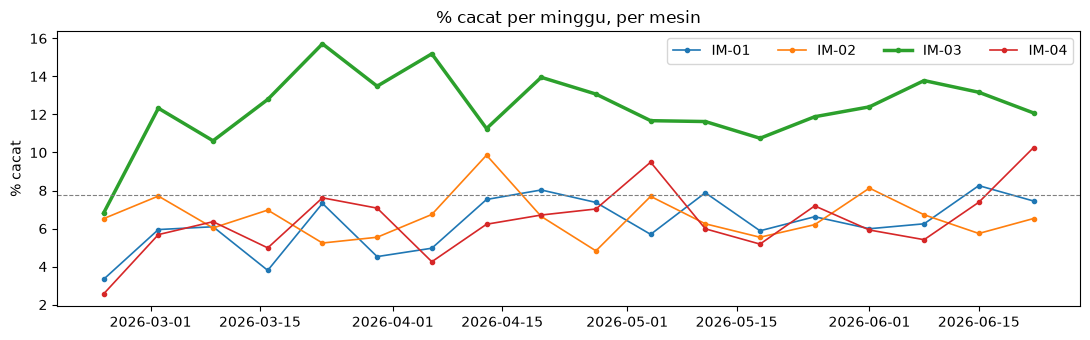

% cacat per bulan:


mesin,IM-01,IM-02,IM-03,IM-04
waktu_produksi,,,,
2026-03,5.6,6.5,12.7,6.1
2026-04,6.3,6.7,13.1,6.1
2026-05,6.8,6.5,11.9,7.0
2026-06,7.0,6.8,12.9,7.2


In [42]:
mingguan = (eda.groupby([eda["waktu_produksi"].dt.to_period("W").dt.start_time, "mesin"])[TARGET]
            .mean().mul(100).unstack())

fig, ax = plt.subplots(figsize=(11, 3.5))
for mesin in mingguan.columns:
    ax.plot(mingguan.index, mingguan[mesin], marker=".", label=mesin,
            linewidth=2.5 if mesin == "IM-03" else 1.2)
garis_rata(ax)
ax.set_ylabel("% cacat")
ax.set_title("% cacat per minggu, per mesin")
ax.legend(ncol=4)
plt.tight_layout()
plt.show()

print("% cacat per bulan:")
pd.crosstab(eda["waktu_produksi"].dt.to_period("M"), eda["mesin"], values=eda[TARGET], aggfunc="mean").mul(100).round(1)

Persentase cacat setiap mesin naik-turun dari minggu ke minggu, tetapi tidak menunjukkan tren naik atau turun yang
jelas dari Maret sampai Juni. IM-03 selalu berada di atas mesin lain sepanjang periode. Karena polanya stabil,
pembagian data secara acak dengan stratifikasi di bagian 6 masih wajar. Sebagai pemeriksaan tambahan, model final bisa
juga diuji dengan melatihnya pada data Maret–Mei dan mengujinya pada data Juni.

In [43]:
# ✅ Cek 4: temuan utama masih berlaku. Jika data atau pembersihan berubah, sel ini berhenti di temuan yang tidak lagi benar.
per_bahan = df.groupby("bahan")[TARGET].mean()
assert per_bahan["PP"] < per_bahan["ABS"] and per_bahan["PP"] < per_bahan["PC"], "PP seharusnya paling jarang cacat."

per_mesin = df.groupby("mesin")[TARGET].mean()
assert per_mesin.idxmax() == "IM-03", "IM-03 seharusnya mesin yang paling sering cacat."

jarak = eda["selisih_leleh"].abs()
assert eda.loc[jarak > 15, TARGET].mean() > 2 * eda.loc[jarak < 5, TARGET].mean(), "Pola U suhu leleh tidak muncul."

higroskopis = eda["bahan"].isin(BAHAN_HIGROSKOPIS)
basah, kering = eda["kelembaban_bahan_pct"] > 0.15, eda["kelembaban_bahan_pct"] < 0.10
assert eda.loc[higroskopis & basah, TARGET].mean() > 3 * eda.loc[higroskopis & kering, TARGET].mean(), \
    "Kelembaban tinggi pada ABS/PC seharusnya jauh lebih sering cacat."

assert "selisih_leleh" not in df.columns, "Kolom bantu EDA tidak boleh masuk ke df."
print("✅ Bagian 4 beres")

✅ Bagian 4 beres


### Ringkasan bagian 4

| Temuan | Bukti | Dampak untuk bagian berikutnya |
|---|---|---|
| Cacat berbentuk **U** terhadap selisih suhu leleh dan suhu cetakan dari standar bahan | Cacat sekitar 4% dalam ±5 °C, sekitar 31% di atas +20 °C | Fitur selisih suhu dan nilai mutlaknya (bagian 5) |
| Kelembaban hanya berpengaruh pada ABS dan PC, dengan **ambang** sekitar 0,10–0,15% | Cacat ABS/PC sekitar 3–4% saat kering, sekitar 65% di atas 0,20%. PP datar | Fitur kelembaban × higroskopis (bagian 5). Cara mengisi kelembaban kosong diuji di bagian 7.3 |
| ABS dan PC lebih sering cacat daripada PP, terutama karena kelembaban | Saat kering, persentase cacatnya setara dengan PP | Sudah tertangkap oleh fitur kelembaban |
| Tekanan rendah dan pendinginan singkat menaikkan cacat (satu arah) | Tekanan < 760 bar: sekitar 26%. Pendinginan < 13 detik: sekitar 14% | Fitur "kekurangan tekanan" untuk regresi logistik. Model pohon bisa menangkapnya sendiri |
| Waktu siklus hanya ikut-ikutan waktu pendinginan | Korelasi 0,89, sisanya tidak berpola | Waspadai saat membaca koefisien regresi logistik |
| Kecepatan injeksi hampir tidak berpengaruh | Lengkungan U yang sangat landai | Tetap dimasukkan, biar model yang menilai |
| **IM-03** sekitar 2× lebih sering cacat karena berjalan sekitar 6 °C lebih panas **dan** faktor mesin lain | Lebih sering cacat walaupun pada selisih suhu yang sama | `mesin` jadi masukan model. Saran untuk klien: periksa IM-03 |
| Tidak ada tren cacat terhadap waktu | Persentase per minggu stabil | Split acak dengan stratifikasi wajar (bagian 6) |

## 5 · Fitur dari pengetahuan proses

Setiap fitur baru berasal dari satu temuan di bagian 4.

| Temuan di bagian 4 | Fitur | Cara menghitung |
|---|---|---|
| Cacat berbentuk U terhadap selisih suhu dari standar bahan (4.2) | `selisih_leleh`, `selisih_cetakan` | Suhu dikurangi suhu standar bahannya |
| | `abs_selisih_leleh`, `abs_selisih_cetakan` | Nilai mutlak selisih, supaya regresi logistik bisa menangkap pola U |
| Kelembaban hanya berpengaruh pada ABS dan PC (4.3) | `kelembaban_higroskopis` | Kelembaban jika bahannya ABS atau PC, 0 jika PP |
| Tekanan rendah menaikkan cacat, tekanan tinggi tidak (4.4) | `kekurangan_tekanan` | 850 dikurangi tekanan, atau 0 jika tekanan sudah 850 bar atau lebih |

Temuan lain tidak perlu fitur baru. Pengaruh IM-03 ditangkap langsung dari kolom `mesin`, dan pengaruh pendinginan yang
terlalu singkat bersifat satu arah sehingga bisa ditangkap dari kolom aslinya.

Fungsinya saya tulis ke `src/features.py`, sehingga notebook dan API memakai kode yang sama untuk menghitung fitur.

### 5.1 Menulis `src/features.py`
Selain fungsi `buat_fitur`, file ini juga menyimpan suhu standar, daftar bahan higroskopis, dan batas tekanan 850 bar.
Dengan begitu API bisa memakai angka yang sama untuk menyusun saran tindakan. Ada tiga aturan yang saya pegang:

- Fungsi mengembalikan salinan, jadi DataFrame aslinya tidak berubah.
- Nilai kosong dibiarkan kosong, karena pengisiannya dilakukan di *pipeline* dengan median dari data train.
  Pengecualiannya `kelembaban_higroskopis` untuk PP, yang selalu 0 karena kelembaban PP tidak berpengaruh.
- Kolom angka diubah ke `float` lebih dulu. API bisa mengirim nilai kosong sebagai `None`, dan tanpa langkah ini
  kolomnya menjadi teks sehingga tidak bisa diisi median di *pipeline*.

In [44]:
%%writefile ../src/features.py
"""Fitur dari pengetahuan proses injection molding.

Dipakai saat pelatihan (notebook) dan saat prediksi (API), supaya cara menghitungnya selalu sama.
File ini dibuat oleh notebook bagian 5. Jika ingin mengubahnya, ubah di notebook lalu jalankan ulang.
"""
import pandas as pd

# suhu standar dari tim proses: (suhu leleh, suhu cetakan) dalam °C
SUHU_STANDAR = {"PP": (230, 40), "ABS": (240, 60), "PC": (300, 90)}
# bahan yang menyerap air dari udara
BAHAN_HIGROSKOPIS = {"ABS", "PC"}
# mulai tekanan ini persentase cacat sudah normal (notebook bagian 4.4)
TEKANAN_CUKUP_BAR = 850

KOLOM_ANGKA = ["suhu_leleh_C", "suhu_cetakan_C", "tekanan_injeksi_bar", "kecepatan_injeksi_mm_s",
               "waktu_pendinginan_s", "waktu_siklus_s", "kelembaban_bahan_pct"]
FITUR_BARU = ["selisih_leleh", "selisih_cetakan", "abs_selisih_leleh", "abs_selisih_cetakan",
              "kelembaban_higroskopis", "kekurangan_tekanan"]


def buat_fitur(df: pd.DataFrame) -> pd.DataFrame:
    """Menerima DataFrame berisi 9 kolom masukan, mengembalikan salinan dengan kolom FITUR_BARU."""
    df = df.copy()
    # nilai kosong dari API bisa berupa None, dan kolomnya jadi bertipe object. Ubah ke float supaya menjadi NaN.
    df[KOLOM_ANGKA] = df[KOLOM_ANGKA].astype(float)
    leleh_standar = df["bahan"].map({b: s[0] for b, s in SUHU_STANDAR.items()})
    cetakan_standar = df["bahan"].map({b: s[1] for b, s in SUHU_STANDAR.items()})

    df["selisih_leleh"] = df["suhu_leleh_C"] - leleh_standar
    df["selisih_cetakan"] = df["suhu_cetakan_C"] - cetakan_standar
    df["abs_selisih_leleh"] = df["selisih_leleh"].abs()
    df["abs_selisih_cetakan"] = df["selisih_cetakan"].abs()

    # PP tidak menyerap air, jadi kelembabannya dianggap 0, termasuk jika kosong
    higroskopis = df["bahan"].isin(BAHAN_HIGROSKOPIS)
    df["kelembaban_higroskopis"] = df["kelembaban_bahan_pct"]
    df.loc[~higroskopis, "kelembaban_higroskopis"] = 0.0

    # seberapa jauh tekanan di bawah batas cukup. Tekanan yang kosong tetap kosong.
    df["kekurangan_tekanan"] = (TEKANAN_CUKUP_BAR - df["tekanan_injeksi_bar"]).clip(lower=0)
    return df

Overwriting ../src/features.py


### 5.2 Mengecek fungsinya
Saya menguji fungsi yang di-*import* dari file, bukan dari sel notebook, dengan tiga cara. Pertama, empat siklus contoh
yang hasilnya saya hitung manual, termasuk siklus dengan tekanan dan kelembaban kosong. Kedua, satu siklus dengan nilai kosong berupa `None`, seperti yang nanti dikirim oleh API. Ketiga, seluruh data bersih:
jumlah baris harus tetap, `df` tidak boleh berubah, dan selisih suhu harus sama dengan yang saya hitung di bagian 4.

In [45]:
# ✅ Cek 5: src/features.py bisa di-import, tidak mengubah data asli, tahan nilai kosong, dan hasilnya sesuai hitungan manual
import importlib
import src.features
importlib.reload(src.features)   # supaya perubahan di sel sebelumnya langsung terbaca
from src.features import buat_fitur, FITUR_BARU

assert src.features.SUHU_STANDAR == SUHU_STANDAR, "SUHU_STANDAR di file berbeda dengan di bagian 1."
assert src.features.BAHAN_HIGROSKOPIS == BAHAN_HIGROSKOPIS, "BAHAN_HIGROSKOPIS di file berbeda dengan di bagian 1."

# 1) Empat siklus contoh yang hasilnya saya hitung manual
contoh = pd.DataFrame({
    "bahan":                ["ABS", "PP", "PC", "PP"],
    "suhu_leleh_C":         [262.0, 220.0, 300.0, 230.0],
    "suhu_cetakan_C":       [61.5, 45.0, 90.0, 40.0],
    "tekanan_injeksi_bar":  [905, 700, np.nan, 850],
    "kelembaban_bahan_pct": [0.18, 0.30, np.nan, np.nan],
})
contoh["mesin"] = "IM-01"   # kolom lain tidak memengaruhi fitur, jadi diisi nilai yang sama
contoh["kecepatan_injeksi_mm_s"] = 80.0
contoh["waktu_pendinginan_s"] = 17.0
contoh["waktu_siklus_s"] = 31.0

harapan = pd.DataFrame({
    "selisih_leleh":          [22.0, -10.0, 0.0, 0.0],
    "selisih_cetakan":        [1.5, 5.0, 0.0, 0.0],
    "abs_selisih_leleh":      [22.0, 10.0, 0.0, 0.0],
    "abs_selisih_cetakan":    [1.5, 5.0, 0.0, 0.0],
    "kelembaban_higroskopis": [0.18, 0.0, np.nan, 0.0],   # PP selalu 0, PC yang kosong tetap kosong
    "kekurangan_tekanan":     [0.0, 150.0, np.nan, 0.0],  # tekanan yang kosong tetap kosong
})
hasil = buat_fitur(contoh)
assert np.allclose(hasil[FITUR_BARU], harapan, equal_nan=True), "Hasil fitur tidak sesuai hitungan manual."
assert "selisih_leleh" not in contoh.columns, "buat_fitur tidak boleh mengubah DataFrame aslinya."

# 2) Satu siklus dari API dengan nilai kosong berupa None
dari_api = pd.DataFrame([{
    "mesin": "IM-03", "bahan": "ABS", "suhu_leleh_C": 262.0, "suhu_cetakan_C": 61.5, "tekanan_injeksi_bar": None,
    "kecepatan_injeksi_mm_s": 80.2, "waktu_pendinginan_s": 17.5, "waktu_siklus_s": 31.0, "kelembaban_bahan_pct": None,
}])
hasil_api = buat_fitur(dari_api)
assert (hasil_api[FITUR_BARU].dtypes == "float64").all(), "Semua fitur harus bertipe angka, bukan teks."
assert hasil_api["kekurangan_tekanan"].isna().all(), "Tekanan None harus menjadi NaN."
assert hasil_api["kelembaban_higroskopis"].isna().all(), "Kelembaban None harus menjadi NaN."

# 3) Data bersih: jumlah baris tetap, df tidak berubah, dan selisih suhu sama dengan hitungan di bagian 4
kolom_awal = list(df.columns)
fitur = buat_fitur(df)
assert len(fitur) == len(df), "Jumlah baris berubah."
assert list(df.columns) == kolom_awal, "df ikut berubah. buat_fitur harus memakai df.copy()."
assert np.allclose(fitur["selisih_leleh"], eda["selisih_leleh"]), "selisih_leleh berbeda dengan bagian 4."
assert np.allclose(fitur["selisih_cetakan"], eda["selisih_cetakan"]), "selisih_cetakan berbeda dengan bagian 4."
assert (fitur["kekurangan_tekanan"].dropna() >= 0).all(), "kekurangan_tekanan tidak boleh negatif."
print("✅ Bagian 5 beres. Fitur baru:", FITUR_BARU)

✅ Bagian 5 beres. Fitur baru: ['selisih_leleh', 'selisih_cetakan', 'abs_selisih_leleh', 'abs_selisih_cetakan', 'kelembaban_higroskopis', 'kekurangan_tekanan']


### 5.3 Membandingkan fitur baru dengan kolom aslinya
Sebagai gambaran awal, saya membandingkan korelasi setiap fitur baru dengan cacat terhadap korelasi kolom asalnya.

In [46]:
kolom_asli = ["suhu_leleh_C", "suhu_cetakan_C", "kelembaban_bahan_pct", "tekanan_injeksi_bar"]
fitur_baru = ["abs_selisih_leleh", "abs_selisih_cetakan", "kelembaban_higroskopis", "kekurangan_tekanan"]
korelasi_asli = fitur[kolom_asli].corrwith(fitur[TARGET])
korelasi_baru = fitur[fitur_baru].corrwith(fitur[TARGET])

print("Korelasi dengan cacat:")
pd.DataFrame({
    "kolom asli": kolom_asli,
    "korelasi kolom asli": korelasi_asli.values,
    "fitur baru": fitur_baru,
    "korelasi fitur baru": korelasi_baru.values,
}).round(3)

Korelasi dengan cacat:


,kolom asli,korelasi kolom asli,fitur baru,korelasi fitur baru
0,suhu_leleh_C,0.112,abs_selisih_leleh,0.183
1,suhu_cetakan_C,0.114,abs_selisih_cetakan,0.107
2,kelembaban_bahan_pct,0.404,kelembaban_higroskopis,0.390
3,tekanan_injeksi_bar,-0.177,kekurangan_tekanan,0.248


Dua fitur jelas lebih berguna daripada kolom aslinya.

- `abs_selisih_leleh` (0,183) lebih berhubungan dengan cacat daripada suhu leleh mentah (0,112). Pola U memang lebih
  tertangkap setelah suhu dibandingkan dengan standar bahannya.
- `kekurangan_tekanan` (0,248) lebih kuat daripada tekanan mentah (−0,177), karena hanya mengukur sisi yang bermasalah,
  yaitu tekanan yang terlalu rendah.

Dua fitur lainnya sedikit di bawah kolom aslinya, yaitu `abs_selisih_cetakan` (0,107 dibanding 0,114) dan
`kelembaban_higroskopis` (0,390 dibanding 0,404). Korelasi kolom asli ikut terbawa perbedaan antarbahan. ABS dan PC
dicetak lebih panas, lebih lembap, dan lebih sering cacat daripada PP, jadi sebagian korelasi kolom asli sebenarnya
mengukur jenis bahan. Informasi bahan itu sendiri sudah masuk ke model lewat kolom `bahan`.

Korelasi hanya mengukur hubungan garis lurus, jadi tabel ini belum cukup untuk memutuskan fitur mana yang dipakai.

### Ringkasan bagian 5

- Enam fitur baru dibuat dari temuan bagian 4 dan disimpan di `src/features.py`, yang juga dipakai oleh API.
- Fungsinya lolos semua pengecekan: hasilnya sesuai hitungan manual, tahan nilai kosong, dan tidak mengubah data asli.
- `abs_selisih_leleh` dan `kekurangan_tekanan` paling jelas menambah informasi dibandingkan kolom aslinya.
- Fitur mana yang akhirnya dipakai, termasuk batas tekanan 850 atau 800 bar, diputuskan dari PR-AUC *validation* di
  bagian 8.

## 6 · Membagi data menjadi train, validation, dan test

Yang saya bagi adalah **data bersih** dari bagian 3, yaitu `data/bersih.csv` yang dibaca ulang sebagai `df` di awal
bagian 4. Jumlahnya 25.000 baris: data mentah 25.350 baris dikurangi 350 duplikat. Data ini saya bagi menjadi tiga.

- **Train** (60%, 15.000 baris): tempat model belajar.
- **Validation** (20%, 5.000 baris): untuk memilih model, fitur, dan *threshold*.
- **Test** (20%, 5.000 baris): ujian akhir. Baru saya buka sekali di bagian 9, setelah semua pilihan final.

Alasan saya memilih 60/20/20: *threshold* dipilih dari jumlah komponen cacat yang lolos dan komponen bagus yang ikut
disisihkan di validation, sehingga validation butuh cukup banyak contoh cacat. Dengan 20%, validation dan test
masing-masing berisi sekitar 388 komponen cacat. Jika memakai 10%, hanya sekitar 194, dan *threshold* serta PR-AUC
mudah berubah karena kebetulan. Train dengan 15.000 baris sudah lebih dari cukup untuk melatih model.

Pembagiannya memakai stratifikasi, supaya proporsi cacat sekitar 7,8% sama di ketiga bagian. Pembagian acak bisa
dipakai karena tidak ada tren cacat terhadap waktu (bagian 4.7), dan duplikat sudah dihapus di bagian 3.2, jadi tidak
ada baris yang sama di train dan test.

Masukan model hanya 9 kolom: `mesin`, `bahan`, dan 7 parameter proses. `shift` tidak dipakai karena labelnya tidak
cocok dengan jam produksi (bagian 3.6), dan `waktu_produksi` tidak dipakai karena tidak diisi oleh operator.

In [47]:
from sklearn.model_selection import train_test_split

FITUR_MASUKAN = ["mesin", "bahan", "suhu_leleh_C", "suhu_cetakan_C", "tekanan_injeksi_bar",
                 "kecepatan_injeksi_mm_s", "waktu_pendinginan_s", "waktu_siklus_s", "kelembaban_bahan_pct"]
# df berisi data bersih (data/bersih.csv, 25.000 baris) yang dibaca ulang di awal bagian 4
X = df[FITUR_MASUKAN]
y = df[TARGET]

# train_test_split hanya bisa membagi dua, jadi dipotong dua kali: 60/40, lalu sisa 40% dibagi dua sama besar
X_train, X_sisa, y_train, y_sisa = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_sisa, y_sisa, test_size=0.5, stratify=y_sisa, random_state=RANDOM_STATE)

pd.DataFrame({
    "jumlah baris": [len(X_train), len(X_val), len(X_test)],
    "jumlah cacat": [y_train.sum(), y_val.sum(), y_test.sum()],
    "% cacat": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["train", "validation", "test"]).round(2)

,jumlah baris,jumlah cacat,% cacat
train,15000,1164,7.76
validation,5000,388,7.76
test,5000,388,7.76


In [48]:
# ✅ Cek 6: yang dibagi data bersih, ukuran setiap bagian benar, proporsi cacat sama, dan tidak ada baris ganda
assert len(df) == 25_000 and df.duplicated().sum() == 0, "Yang dibagi harus data bersih (25.000 baris tanpa duplikat)."
assert (len(X_train), len(X_val), len(X_test)) == (15_000, 5_000, 5_000), "Ukuran split harus 15.000 / 5.000 / 5.000."
assert abs(y_train.mean() - y.mean()) < 0.003, "Proporsi cacat di train melenceng. Sudah pakai stratify?"
assert abs(y_val.mean() - y.mean()) < 0.003, "Proporsi cacat di validation melenceng. Sudah pakai stratify?"
assert abs(y_test.mean() - y.mean()) < 0.003, "Proporsi cacat di test melenceng. Sudah pakai stratify?"
assert X_train.index.intersection(X_val.index).empty, "Ada baris yang masuk ke train dan validation sekaligus."
assert X_train.index.intersection(X_test.index).empty, "Ada baris yang masuk ke train dan test sekaligus."
assert X_val.index.intersection(X_test.index).empty, "Ada baris yang masuk ke validation dan test sekaligus."
assert list(X.columns) == FITUR_MASUKAN, "Masukan model harus 9 kolom, tanpa shift dan waktu_produksi."
print("✅ Bagian 6 beres:", len(X_train), "/", len(X_val), "/", len(X_test), "baris")

✅ Bagian 6 beres: 15000 / 5000 / 5000 baris


Proporsi cacat di ketiga bagian sama, yaitu 7,76%, dengan 388 komponen cacat di validation dan di test. Mulai dari sini
`X_test` dan `y_test` tidak saya sentuh sampai bagian 9.

### Ringkasan bagian 6

- Data bersih 25.000 baris dibagi 15.000 / 5.000 / 5.000 (60/20/20) dengan stratifikasi dan `random_state = 42`.
- Proporsi cacat sama di ketiga bagian, dan tidak ada baris yang masuk ke dua bagian sekaligus.
- Masukan model 9 kolom. Data test dikunci sampai bagian 9.

## 7 · *Baseline* wajib: regresi logistik

*Baseline* saya berupa regresi logistik dengan fitur asli, yaitu model paling sederhana untuk masalah ini. Model lain
di bagian 8 dianggap berguna hanya jika lebih baik dari angka ini.

Semua langkah saya bungkus dalam satu *pipeline*, supaya tidak ada langkah yang terlewat saat model dipakai di API:

`data mentah 9 kolom → isi nilai kosong + samakan skala → one-hot mesin dan bahan → regresi logistik → peluang cacat`

- Nilai kosong diisi median, dan median itu hanya dihitung dari data train saat `fit`. Jadi tidak ada informasi dari
  validation atau test yang bocor ke model.
- `StandardScaler` menyamakan skala kolom angka. Regresi logistik peka terhadap skala: tekanan bernilai ratusan,
  sedangkan kelembaban di bawah 1.
- `mesin` dan `bahan` diubah menjadi kolom 0/1 dengan *one-hot*.
- *Baseline* memakai **fitur asli saja**, tanpa `buat_fitur`.

### 7.1 Melatih *baseline*

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

KOLOM_KATEGORI = ["mesin", "bahan"]


def buat_pipeline_asli(model):
    # pipeline untuk 9 kolom asli: isi nilai kosong dan samakan skala untuk angka, one-hot untuk kategori
    preprocess = ColumnTransformer([
        ("angka", Pipeline([("isi_kosong", SimpleImputer(strategy="median")), ("skala", StandardScaler())]), KOLOM_ANGKA),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), KOLOM_KATEGORI),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])


baseline = buat_pipeline_asli(LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)

proba_val_baseline = baseline.predict_proba(X_val)[:, 1]
pr_auc_baseline = average_precision_score(y_val, proba_val_baseline)
print(f"PR-AUC validation baseline        : {pr_auc_baseline:.3f}")
print(f"Patokan tebak acak (proporsi cacat): {y_val.mean():.3f}")

PR-AUC validation baseline        : 0.474
Patokan tebak acak (proporsi cacat): 0.078


PR-AUC *baseline* sekitar 0,47, kira-kira enam kali patokan tebak acak (0,078). Regresi logistik dengan kolom asli
sudah bisa membedakan siklus berisiko, tetapi masih jauh dari 1. Ini wajar, karena *baseline* belum memakai fitur
dari bagian 5: model ini tidak tahu standar suhu tiap bahan dan tidak bisa menangkap pola U.

### 7.2 Kurva *precision-recall*
PR-AUC adalah luas di bawah kurva ini. Kurva menunjukkan *trade-off*-nya: semakin banyak komponen cacat yang ingin
ditangkap (*recall* naik), semakin banyak komponen bagus yang ikut disisihkan (*precision* turun).

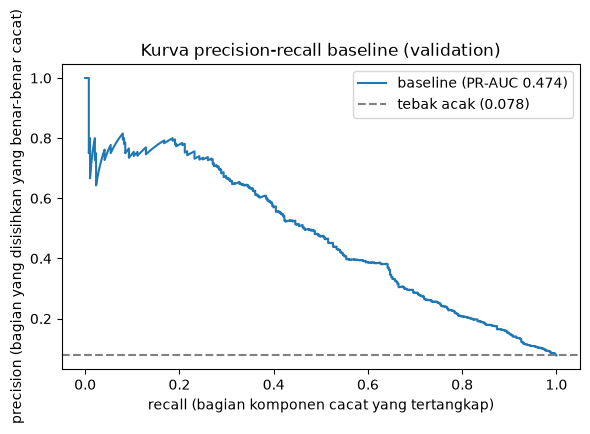

In [50]:
precision, recall, _ = precision_recall_curve(y_val, proba_val_baseline)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision, label=f"baseline (PR-AUC {pr_auc_baseline:.3f})")
ax.axhline(y_val.mean(), color="grey", linestyle="--", label=f"tebak acak ({y_val.mean():.3f})")
ax.set_xlabel("recall (bagian komponen cacat yang tertangkap)")
ax.set_ylabel("precision (bagian yang disisihkan yang benar-benar cacat)")
ax.set_title("Kurva precision-recall baseline (validation)")
ax.legend()
plt.tight_layout()
plt.show()

Untuk menangkap separuh komponen cacat, sekitar separuh komponen yang disisihkan memang cacat (*precision* sekitar
0,47). Jika ingin menangkap 90% komponen cacat, *precision* turun menjadi sekitar 0,15, artinya dari setiap 100
komponen yang disisihkan hanya sekitar 15 yang benar-benar cacat. Titik mana yang dipakai ditentukan oleh biaya di
bagian 7.4.

### 7.3 Mengisi kelembaban yang kosong: median gabungan atau per bahan?
Di bagian 4.3 saya menduga median per bahan lebih tepat, karena median kelembaban PP jauh lebih rendah daripada ABS dan
PC. Saya uji dengan mengisi kelembaban yang kosong memakai median per bahan dari data train, lalu membandingkan PR-AUC
validation-nya dengan *baseline*.

In [51]:
median_per_bahan = X_train.groupby("bahan")["kelembaban_bahan_pct"].median()   # dihitung dari train saja


def isi_kelembaban_per_bahan(data):
    data = data.copy()
    data["kelembaban_bahan_pct"] = data["kelembaban_bahan_pct"].fillna(data["bahan"].map(median_per_bahan))
    return data


uji_per_bahan = buat_pipeline_asli(LogisticRegression(max_iter=1000))
uji_per_bahan.fit(isi_kelembaban_per_bahan(X_train), y_train)
pr_auc_per_bahan = average_precision_score(y_val, uji_per_bahan.predict_proba(isi_kelembaban_per_bahan(X_val))[:, 1])

print("Median kelembaban train per bahan:", median_per_bahan.round(3).to_dict())
print(f"Median kelembaban train gabungan : {X_train['kelembaban_bahan_pct'].median():.3f}")
print(f"Kelembaban kosong di validation  : {X_val['kelembaban_bahan_pct'].isna().sum()} dari {len(X_val):,} baris\n")
print(f"PR-AUC validation, median gabungan: {pr_auc_baseline:.4f}")
print(f"PR-AUC validation, median per bahan: {pr_auc_per_bahan:.4f}")

Median kelembaban train per bahan: {'ABS': 0.074, 'PC': 0.075, 'PP': 0.017}
Median kelembaban train gabungan : 0.033
Kelembaban kosong di validation  : 202 dari 5,000 baris

PR-AUC validation, median gabungan: 0.4739
PR-AUC validation, median per bahan: 0.4757


Median per bahan memang berbeda jauh (PP 0,017%, ABS dan PC sekitar 0,075%), tetapi PR-AUC hanya naik sekitar 0,002.
Kelembaban yang kosong hanya sekitar 4% baris, dan median ABS/PC (0,075%) masih di bawah ambang 0,10% tempat cacat mulai
naik. Jadi mengisi dengan median gabungan atau per bahan sama-sama menganggap bahan itu "kering".

Karena selisihnya sangat kecil, saya tetap memakai `SimpleImputer` dengan median gabungan. Cara ini lebih sederhana,
dan seluruh langkahnya tetap berada di dalam satu *pipeline* yang sama dengan yang dipakai API.

### 7.4 *Threshold* sementara dan menyimpan *baseline*
Model memberi peluang antara 0 dan 1. *Threshold* adalah batas mulai dari peluang berapa komponen disisihkan. Asumsi
biayanya: komponen cacat yang lolos ke pelanggan merugikan Rp500.000 (klaim dan reputasi), sedangkan komponen bagus
yang ikut disisihkan merugikan Rp25.000. Untuk setiap kandidat *threshold* saya hitung total biayanya di data validation, lalu memilih yang
paling murah.

*Threshold* ini masih sementara. *Baseline* saya simpan sekarang supaya aplikasi bisa di-*deploy* lebih awal. Model
dan *threshold* final ditentukan di bagian 9, dan data test belum dibuka.

Threshold termurah: 0.05
Cacat tertangkap  : 326 dari 388   |   komponen bagus ikut disisihkan: 1380 dari 4612
Total biaya validation:
  baseline + threshold    : Rp 65.5 juta
  semua diloloskan        : Rp 194.0 juta
  semua disisihkan        : Rp 115.3 juta


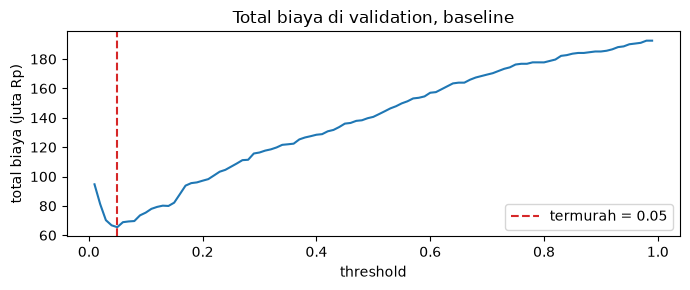

In [52]:
BIAYA_FN = 500_000   # kerugian per komponen cacat yang lolos ke pelanggan (klaim dan reputasi)
BIAYA_FP = 25_000    # kerugian per komponen bagus yang ikut disisihkan


def total_biaya(y_benar, proba, threshold):
    tn, fp, fn, tp = confusion_matrix(y_benar, proba >= threshold).ravel()
    return fn * BIAYA_FN + fp * BIAYA_FP


kandidat = np.round(np.arange(0.01, 1.00, 0.01), 2)
biaya_baseline = [total_biaya(y_val, proba_val_baseline, t) for t in kandidat]
threshold_baseline = float(kandidat[int(np.argmin(biaya_baseline))])

tn, fp, fn, tp = confusion_matrix(y_val, proba_val_baseline >= threshold_baseline).ravel()
print(f"Threshold termurah: {threshold_baseline:.2f}")
print(f"Cacat tertangkap  : {tp} dari {tp + fn}   |   komponen bagus ikut disisihkan: {fp} dari {tn + fp}")
print(f"Total biaya validation:")
print(f"  baseline + threshold    : Rp {min(biaya_baseline) / 1e6:,.1f} juta")
print(f"  semua diloloskan        : Rp {y_val.sum() * BIAYA_FN / 1e6:,.1f} juta")
print(f"  semua disisihkan        : Rp {(y_val == 0).sum() * BIAYA_FP / 1e6:,.1f} juta")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(kandidat, np.array(biaya_baseline) / 1e6)
ax.axvline(threshold_baseline, color="tab:red", linestyle="--", label=f"termurah = {threshold_baseline:.2f}")
ax.set_xlabel("threshold")
ax.set_ylabel("total biaya (juta Rp)")
ax.set_title("Total biaya di validation, baseline")
ax.legend()
plt.tight_layout()
plt.show()

*Threshold* termurah adalah 0,05, jauh di bawah 0,5. Angka ini cocok dengan hitungan sederhana: menyisihkan sebuah
komponen lebih murah jika peluang cacatnya di atas 25.000 / (25.000 + 500.000) ≈ 0,048. Karena komponen cacat yang
lolos 20 kali lebih mahal, model memang harus "gampang curiga".

Dengan *threshold* ini, *baseline* menangkap 326 dari 388 komponen cacat, tetapi ikut menyisihkan 1.380 komponen bagus.
Total biayanya sekitar Rp65,5 juta, jauh lebih murah daripada meloloskan semua komponen seperti sekarang (Rp194 juta)
maupun menyisihkan semuanya (Rp115 juta).

Selanjutnya *baseline* saya simpan ke `artifacts/` dengan versi `0.1.0`, lengkap dengan catatannya di `metadata.json`.
Metrik test sengaja dikosongkan karena data test belum dibuka.

In [53]:
import joblib
import sklearn
import xgboost


def simpan_artefak(model, metadata):
    joblib.dump(model, ROOT / "artifacts" / "model.joblib")
    with open(ROOT / "artifacts" / "metadata.json", "w", encoding="utf-8") as f:
        json.dump(metadata, f, indent=2, ensure_ascii=False)


KOLOM_OPSIONAL = ["tekanan_injeksi_bar", "waktu_pendinginan_s", "waktu_siklus_s", "kelembaban_bahan_pct"]
# rentang nilai yang pernah dilihat model (dari train). API memberi peringatan jika masukan di luar rentang ini.
rentang_data_latih = X_train[KOLOM_ANGKA].agg(["min", "max"]).round(3).to_dict(orient="list")
versi_library = {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__}

metadata_baseline = {
    "versi_model": "0.1.0",
    "tanggal_latih": time.strftime("%Y-%m-%d"),
    "nama_model": "Baseline: regresi logistik dengan fitur asli",
    "fitur_masukan": FITUR_MASUKAN,
    "kolom_opsional": KOLOM_OPSIONAL,
    "kategori": {"mesin": sorted(df["mesin"].unique()), "bahan": list(SUHU_STANDAR)},
    "rentang_data_latih": rentang_data_latih,
    "threshold": threshold_baseline,
    "alasan_threshold": "Total biaya termurah di data validation (FN Rp500.000, FP Rp25.000). Sementara untuk baseline.",
    "biaya": {"fn": BIAYA_FN, "fp": BIAYA_FP},
    "metrik": {
        "baseline_pr_auc_validation": round(float(pr_auc_baseline), 3),
        "pr_auc_validation": round(float(pr_auc_baseline), 3),
        "pr_auc_test": None,
        "recall_test": None,
        "precision_test": None,
    },
    "versi_library": versi_library,
}
simpan_artefak(baseline, metadata_baseline)
print(json.dumps(metadata_baseline, indent=2, ensure_ascii=False))

{
  "versi_model": "0.1.0",
  "tanggal_latih": "2026-11-20",
  "nama_model": "Baseline: regresi logistik dengan fitur asli",
  "fitur_masukan": [
    "mesin",
    "bahan",
    "suhu_leleh_C",
    "suhu_cetakan_C",
    "tekanan_injeksi_bar",
    "kecepatan_injeksi_mm_s",
    "waktu_pendinginan_s",
    "waktu_siklus_s",
    "kelembaban_bahan_pct"
  ],
  "kolom_opsional": [
    "tekanan_injeksi_bar",
    "waktu_pendinginan_s",
    "waktu_siklus_s",
    "kelembaban_bahan_pct"
  ],
  "kategori": {
    "mesin": [
      "IM-01",
      "IM-02",
      "IM-03",
      "IM-04"
    ],
    "bahan": [
      "PP",
      "ABS",
      "PC"
    ]
  },
  "rentang_data_latih": {
    "suhu_leleh_C": [
      195.5,
      336.9
    ],
    "suhu_cetakan_C": [
      8.0,
      112.7
    ],
    "tekanan_injeksi_bar": [
      431.0,
      1310.0
    ],
    "kecepatan_injeksi_mm_s": [
      26.1,
      136.6
    ],
    "waktu_pendinginan_s": [
      6.0,
      34.3
    ],
    "waktu_siklus_s": [
      16.2,
      

In [54]:
# ✅ Cek 7: baseline jauh di atas tebak acak, dan model yang dimuat ulang dari file memberi hasil yang sama
assert pr_auc_baseline > 3 * y_val.mean(), "PR-AUC baseline seharusnya jauh di atas tebak acak."
assert threshold_baseline < 0.5, "Threshold termurah seharusnya di bawah 0,5, karena FN jauh lebih mahal."
assert min(biaya_baseline) < (y_val == 0).sum() * BIAYA_FP, "Baseline harus lebih murah daripada menyisihkan semua."

model_file = joblib.load(ROOT / "artifacts" / "model.joblib")
meta_file = json.load(open(ROOT / "artifacts" / "metadata.json", encoding="utf-8"))
assert np.allclose(model_file.predict_proba(X_val)[:, 1], proba_val_baseline), "Model dari file memberi hasil berbeda."
assert meta_file["fitur_masukan"] == FITUR_MASUKAN, "fitur_masukan di metadata harus 9 kolom dengan urutan yang sama."
assert meta_file["threshold"] == threshold_baseline, "threshold di metadata harus hasil bagian 7.4."

# satu siklus dari API dengan kolom opsional kosong tetap harus mendapat jawaban
siklus = pd.DataFrame([{
    "mesin": "IM-03", "bahan": "ABS", "suhu_leleh_C": 262.0, "suhu_cetakan_C": 61.5, "tekanan_injeksi_bar": None,
    "kecepatan_injeksi_mm_s": 80.2, "waktu_pendinginan_s": 17.5, "waktu_siklus_s": 31.0, "kelembaban_bahan_pct": None,
}])[meta_file["fitur_masukan"]]
peluang = model_file.predict_proba(siklus)[0, 1]
assert 0 <= peluang <= 1, "Peluang harus di antara 0 dan 1."
print(f"✅ Bagian 7 beres. Baseline v{meta_file['versi_model']} tersimpan, threshold {meta_file['threshold']}, "
      f"contoh siklus dengan kolom kosong: peluang cacat {peluang:.3f}")

✅ Bagian 7 beres. Baseline v0.1.0 tersimpan, threshold 0.05, contoh siklus dengan kolom kosong: peluang cacat 0.060


### Ringkasan bagian 7

- *Baseline* regresi logistik dengan fitur asli mendapat PR-AUC validation sekitar 0,47, kira-kira enam kali tebak acak.
  Angka ini menjadi pembanding semua model di bagian 8.
- Mengisi kelembaban kosong dengan median per bahan hanya menaikkan PR-AUC sekitar 0,002, jadi saya tetap memakai
  median gabungan di dalam *pipeline*.
- *Threshold* termurah 0,05, sesuai hitungan biaya. Total biaya validation sekitar Rp65,5 juta, dibanding Rp194 juta
  jika semua komponen diloloskan.
- *Baseline* tersimpan di `artifacts/` sebagai versi `0.1.0`, bisa dimuat ulang dari file, dan tetap bisa memprediksi
  walaupun kolom opsional kosong. Artefak ini dipakai untuk *deploy* pertama aplikasi.

## 8 · Model lain

Di bagian ini saya mencoba model yang lebih baik dari *baseline* (PR-AUC validation 0,474). Semua model dinilai dengan
cara yang sama: dilatih di train, lalu dihitung PR-AUC-nya di validation. Data test tetap belum dibuka.

Saya mencoba dua arah:

1. **Menambah fitur dari bagian 5** ke regresi logistik, untuk membuktikan bahwa fitur dari pengetahuan proses memang
   membantu.
2. **XGBoost**, model berbasis pohon yang bisa menangkap pola tidak lurus, seperti pola U dan "lutut" tekanan, dengan
   sendirinya.

Aturan memilih model final: PR-AUC validation tertinggi. Jika selisihnya kurang dari 0,01, saya pilih regresi logistik
karena lebih mudah dijelaskan ke operator.

### 8.1 Regresi logistik dengan fitur dari bagian 5
*Pipeline*-nya sama dengan *baseline*, tetapi diawali `buat_fitur` dari `src/features.py`. Saya menambahkan fitur secara
bertahap, supaya terlihat sumbangan setiap kelompok fitur.

In [55]:
from sklearn.preprocessing import FunctionTransformer

FITUR_SUHU = ["selisih_leleh", "selisih_cetakan", "abs_selisih_leleh", "abs_selisih_cetakan"]


def buat_pipeline_fitur(model, kolom_angka, fungsi_fitur=buat_fitur):
    # bawaannya buat_fitur dari src/features.py, sehingga model yang disimpan memakai fungsi yang sama dengan API
    preprocess = ColumnTransformer([
        ("angka", Pipeline([("isi_kosong", SimpleImputer(strategy="median")), ("skala", StandardScaler())]), kolom_angka),
        ("kategori", OneHotEncoder(handle_unknown="ignore"), KOLOM_KATEGORI),
    ])
    return Pipeline([("fitur", FunctionTransformer(fungsi_fitur)), ("preprocess", preprocess), ("model", model)])


def pr_auc_validation(pipeline):
    # latih di train, nilai di validation
    pipeline.fit(X_train, y_train)
    return average_precision_score(y_val, pipeline.predict_proba(X_val)[:, 1])


lr_suhu = pr_auc_validation(buat_pipeline_fitur(LogisticRegression(max_iter=1000), KOLOM_ANGKA + FITUR_SUHU))
lr_suhu_lembap = pr_auc_validation(buat_pipeline_fitur(
    LogisticRegression(max_iter=1000), KOLOM_ANGKA + FITUR_SUHU + ["kelembaban_higroskopis"]))

lr_fitur = buat_pipeline_fitur(LogisticRegression(max_iter=1000), KOLOM_ANGKA + FITUR_BARU)
pr_auc_lr_fitur = pr_auc_validation(lr_fitur)

pd.DataFrame({
    "kolom yang dipakai": ["kolom asli (baseline)", "+ selisih suhu", "+ kelembaban higroskopis",
                           "+ kekurangan tekanan (semua fitur)"],
    "PR-AUC validation": [pr_auc_baseline, lr_suhu, lr_suhu_lembap, pr_auc_lr_fitur],
}).round(3)

,kolom yang dipakai,PR-AUC validation
0,kolom asli (baseline),0.474
1,+ selisih suhu,0.583
2,+ kelembaban higroskopis,0.585
3,+ kekurangan tekanan (semua fitur),0.605


Fitur dari bagian 5 menaikkan PR-AUC regresi logistik dari 0,474 menjadi 0,605. Sumbangan terbesar datang dari selisih
suhu (naik sekitar 0,11), karena regresi logistik akhirnya bisa menangkap pola U. Kekurangan tekanan menambah sekitar
0,02, karena model bisa membedakan tekanan yang terlalu rendah dari tekanan yang cukup.

Kelembaban higroskopis hampir tidak menambah apa-apa (sekitar 0,002). Informasinya sudah tertangkap oleh kolom
kelembaban asli ditambah kolom `bahan`. Fitur ini tetap saya pakai karena tidak merugikan, dan berguna untuk model
berbasis pohon di bagian 8.3.

### 8.2 Batas tekanan: 850 atau 800 bar?
Di bagian 5, `kekurangan_tekanan` memakai batas 850 bar. Saya cek dulu persentase cacat per rentang tekanan di data
train, lalu membandingkan batas 850 bar dengan 800 bar. Untuk mencoba 800 bar, angka `TEKANAN_CUKUP_BAR` di
`src/features.py` saya ubah sementara, lalu saya kembalikan.

In [56]:
rentang_tekanan = pd.cut(X_train["tekanan_injeksi_bar"], [0, 700, 760, 800, 850, 900, 1400])
print("% cacat per rentang tekanan (data train):")
print((y_train.groupby(rentang_tekanan, observed=True).mean() * 100).round(1).to_string())
print()

src.features.TEKANAN_CUKUP_BAR = 800   # sementara, hanya untuk perbandingan
pr_auc_tekanan_800 = pr_auc_validation(buat_pipeline_fitur(LogisticRegression(max_iter=1000), KOLOM_ANGKA + FITUR_BARU))
src.features.TEKANAN_CUKUP_BAR = 850   # dikembalikan ke nilai di file

print(f"PR-AUC validation, batas 850 bar: {pr_auc_lr_fitur:.4f}")
print(f"PR-AUC validation, batas 800 bar: {pr_auc_tekanan_800:.4f}")

% cacat per rentang tekanan (data train):
tekanan_injeksi_bar
(0, 700]       37.4
(700, 760]     22.0
(760, 800]      9.7
(800, 850]      7.0
(850, 900]      4.5
(900, 1400]     5.1

PR-AUC validation, batas 850 bar: 0.6046
PR-AUC validation, batas 800 bar: 0.6053


Persentase cacat terus turun saat tekanan naik: sekitar 37% di bawah 700 bar, lalu 7,0% di 800–850 bar, dan datar di
sekitar 5% mulai 850 bar. Ini sejalan dengan bagian 4.4, yang menunjukkan cacat mulai datar di sekitar 850–870 bar.

Bagi model, kedua batas sama baiknya, karena selisih PR-AUC-nya kurang dari 0,001. Saya tetap memakai **850 bar**,
karena di titik itu persentase cacat sudah kembali normal. Batas 800 bar akan menganggap tekanan 800–850 bar sudah
cukup, padahal cacatnya masih sekitar 7%. Angka yang sama dipakai untuk saran tindakan di aplikasi: jika tekanan di
bawah 850 bar, operator disarankan menaikkannya.

### 8.3 XGBoost
Regresi logistik hanya bisa mempelajari hubungan lurus, sehingga pola U dan "lutut" perlu dibantu dengan fitur.
XGBoost membuat pohon keputusan satu per satu, dan setiap pohon baru fokus memperbaiki kesalahan pohon sebelumnya.
Model seperti ini bisa menangkap pola tidak lurus dengan sendirinya.

Komponen bagus jauh lebih banyak daripada yang cacat, sekitar 12 berbanding 1. Tanpa penyesuaian, model cenderung
mengikuti mayoritas dan menebak "lolos". `scale_pos_weight` memberi tahu XGBoost bahwa satu komponen cacat bobotnya
sekitar 12 kali komponen bagus. Efek
pembobotan ini terhadap angka peluang saya periksa di bagian 8.4.

Saya mencoba tiga kedalaman pohon (`max_depth`). Pohon yang lebih dalam bisa menangkap pola yang lebih rumit, tetapi
juga lebih mudah menghafal data train. Sebagai pembanding, saya juga melatih XGBoost tanpa fitur dari bagian 5.

In [57]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.1f}\n")


def buat_xgb(kedalaman):
    return XGBClassifier(n_estimators=300, max_depth=kedalaman, learning_rate=0.05,
                         scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1)


xgb_kedalaman_2 = buat_pipeline_fitur(buat_xgb(2), KOLOM_ANGKA + FITUR_BARU)
pr_auc_xgb_2 = pr_auc_validation(xgb_kedalaman_2)
pr_auc_xgb_3 = pr_auc_validation(buat_pipeline_fitur(buat_xgb(3), KOLOM_ANGKA + FITUR_BARU))
pr_auc_xgb_4 = pr_auc_validation(buat_pipeline_fitur(buat_xgb(4), KOLOM_ANGKA + FITUR_BARU))
pr_auc_xgb_asli = pr_auc_validation(buat_pipeline_fitur(buat_xgb(2), KOLOM_ANGKA))

pd.DataFrame({
    "model": ["XGBoost, max_depth 2", "XGBoost, max_depth 3", "XGBoost, max_depth 4",
              "XGBoost, max_depth 2, tanpa fitur bagian 5"],
    "PR-AUC validation": [pr_auc_xgb_2, pr_auc_xgb_3, pr_auc_xgb_4, pr_auc_xgb_asli],
}).round(3)

scale_pos_weight = 11.9



,model,PR-AUC validation
0,"XGBoost, max_depth 2",0.655
1,"XGBoost, max_depth 3",0.646
2,"XGBoost, max_depth 4",0.632
3,"XGBoost, max_depth 2, tanpa fitur bagian 5",0.600


XGBoost dengan pohon yang dangkal (`max_depth` 2) paling baik, dengan PR-AUC sekitar 0,655. Semakin dalam pohonnya,
PR-AUC justru turun, tanda bahwa pohon yang lebih dalam mulai menghafal data train. Pola cacat di data ini ternyata
cukup sederhana: kebanyakan berupa pengaruh satu atau dua parameter sekaligus.

Fitur dari bagian 5 tetap membantu XGBoost. Tanpa fitur itu, PR-AUC-nya turun ke sekitar 0,60, hampir sama dengan
regresi logistik yang memakai fitur. Artinya fitur dari pengetahuan proses memberi informasi yang sulit ditemukan
sendiri oleh model, misalnya standar suhu yang berbeda untuk setiap bahan.

### 8.4 Apakah peluang dari model bisa dibaca apa adanya?
Aplikasi menampilkan peluang cacat kepada operator, jadi angkanya harus bisa dibaca apa adanya. Dari semua komponen yang
diberi peluang sekitar 50%, seharusnya memang sekitar separuhnya yang cacat. `scale_pos_weight` membuat model
menganggap satu komponen cacat sama pentingnya dengan 12 komponen bagus, sehingga peluangnya bisa ikut membesar.

Saya bandingkan XGBoost dengan dan tanpa `scale_pos_weight`. Peluang dari model saya kelompokkan, lalu di setiap
kelompok saya bandingkan rata-rata peluangnya dengan persentase cacat yang sebenarnya di validation. Saya juga
menghitung *Brier score*, yaitu rata-rata kuadrat selisih antara peluang dan hasil sebenarnya. Semakin kecil nilainya,
semakin tepat peluangnya.

In [58]:
from sklearn.metrics import brier_score_loss

xgb_tanpa_bobot = buat_pipeline_fitur(
    XGBClassifier(n_estimators=300, max_depth=2, learning_rate=0.05, random_state=RANDOM_STATE, n_jobs=-1),
    KOLOM_ANGKA + FITUR_BARU)
pr_auc_xgb_tanpa_bobot = pr_auc_validation(xgb_tanpa_bobot)

proba_dengan_bobot = xgb_kedalaman_2.predict_proba(X_val)[:, 1]
proba_tanpa_bobot = xgb_tanpa_bobot.predict_proba(X_val)[:, 1]


def cek_peluang(proba):
    # kelompokkan peluang dari model, lalu bandingkan dengan persentase cacat sebenarnya di setiap kelompok
    tabel = pd.DataFrame({"peluang dari model": proba, "cacat sebenarnya": y_val.values})
    kelompok = pd.cut(tabel["peluang dari model"], [0, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0])
    hasil = tabel.groupby(kelompok, observed=True).mean()
    hasil["jumlah komponen"] = tabel.groupby(kelompok, observed=True).size()
    hasil.index.name = "kelompok peluang"
    return hasil.round(3)


print(f"Proporsi cacat sebenarnya di validation: {y_val.mean():.3f}")
print(f"                      dengan bobot | tanpa bobot")
print(f"Rata-rata peluang   : {proba_dengan_bobot.mean():12.3f} | {proba_tanpa_bobot.mean():.3f}")
print(f"Brier score         : {brier_score_loss(y_val, proba_dengan_bobot):12.4f} | {brier_score_loss(y_val, proba_tanpa_bobot):.4f}")
print(f"PR-AUC validation   : {pr_auc_xgb_2:12.3f} | {pr_auc_xgb_tanpa_bobot:.3f}")
print()
print("Dengan scale_pos_weight:")
print(cek_peluang(proba_dengan_bobot).to_string())
print()
print("Tanpa scale_pos_weight:")
print(cek_peluang(proba_tanpa_bobot).to_string())

Proporsi cacat sebenarnya di validation: 0.078
                      dengan bobot | tanpa bobot
Rata-rata peluang   :        0.249 | 0.077
Brier score         :       0.0940 | 0.0416
PR-AUC validation   :        0.655 | 0.658

Dengan scale_pos_weight:
                  peluang dari model  cacat sebenarnya  jumlah komponen
kelompok peluang                                                       
(0.0, 0.05]                    0.033             0.003             1166
(0.05, 0.1]                    0.072             0.007             1032
(0.1, 0.2]                     0.142             0.014              915
(0.2, 0.4]                     0.288             0.039              746
(0.4, 0.6]                     0.487             0.075              439
(0.6, 0.8]                     0.700             0.229              319
(0.8, 1.0]                     0.911             0.601              383

Tanpa scale_pos_weight:
                  peluang dari model  cacat sebenarnya  jumlah komponen
kel

Dengan `scale_pos_weight`, peluang dari model jauh lebih tinggi daripada kenyataan. Rata-ratanya sekitar 0,25, padahal
proporsi cacat hanya sekitar 0,08. Dari komponen yang diberi peluang sekitar 49%, ternyata hanya sekitar 7,5% yang
cacat. Jika angka ini ditampilkan di aplikasi, operator akan mengira risikonya jauh lebih besar daripada sebenarnya.

Tanpa `scale_pos_weight`, peluangnya hampir sama dengan kenyataan di setiap kelompok, dan *Brier score*-nya turun lebih
dari separuh, dari sekitar 0,094 menjadi 0,042. Selisih terbesar ada di kelompok 40–60% (model 0,49, kenyataan 0,58).
Kelompok itu hanya berisi sekitar 125 komponen, jadi selisih sebesar itu masih bisa terjadi karena kebetulan. PR-AUC-nya
tetap setara (0,658 dibanding 0,655), karena pembobotan hanya menggeser angka peluang, bukan urutan komponen dari yang
paling berisiko.

Karena itu model final saya adalah XGBoost **tanpa** `scale_pos_weight`. Pembobotan tidak diperlukan untuk menangkap
komponen cacat, karena *threshold* yang rendah di bagian 9 sudah membuat model "gampang curiga". Keuntungan lainnya,
karena peluangnya sesuai kenyataan, *threshold* bisa langsung dihitung dari biaya.

### 8.5 Fitur yang paling dipakai model final

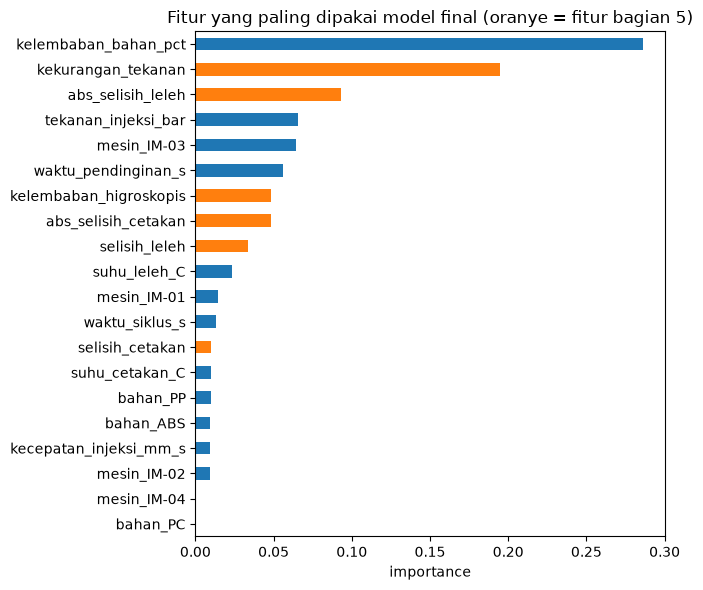

In [59]:
nama_fitur = [n.split("__")[1] for n in xgb_tanpa_bobot.named_steps["preprocess"].get_feature_names_out()]
penting = pd.Series(xgb_tanpa_bobot.named_steps["model"].feature_importances_, index=nama_fitur).sort_values()

plt.figure(figsize=(7, 6))
penting.plot.barh(color=["tab:orange" if n in FITUR_BARU else "tab:blue" for n in penting.index])
plt.title("Fitur yang paling dipakai model final (oranye = fitur bagian 5)")
plt.xlabel("importance")
plt.tight_layout()
plt.show()

Urutannya sesuai dengan temuan EDA di bagian 4.

- **Kelembaban** paling banyak dipakai, sejalan dengan lonjakan cacat ABS dan PC di atas 0,15% (bagian 4.3).
- **Kekurangan tekanan** berada di urutan kedua, dan **tekanan injeksi** juga cukup sering dipakai, sesuai "lutut"
  tekanan di bagian 4.4.
- **Jarak suhu leleh dari standar** (`abs_selisih_leleh`) di urutan ketiga, jauh di atas suhu leleh mentah, karena pola
  U-nya sudah tertangkap.
- **IM-03** muncul sebagai satu-satunya mesin yang cukup dipakai, sesuai bagian 4.5.
- **Kecepatan injeksi** dan **waktu siklus** hampir tidak dipakai, sesuai temuan bahwa keduanya hampir tidak
  berpengaruh.

Karena urutan ini masuk akal secara proses, saya lebih yakin model tidak sekadar menghafal kebetulan di data train.

### 8.6 Memilih model final

In [60]:
perbandingan_model = pd.DataFrame({
    "model": ["Baseline: regresi logistik, fitur asli",
              "Regresi logistik + fitur bagian 5",
              "XGBoost + fitur bagian 5, dengan scale_pos_weight",
              "XGBoost + fitur bagian 5, tanpa scale_pos_weight"],
    "PR-AUC validation": [pr_auc_baseline, pr_auc_lr_fitur, pr_auc_xgb_2, pr_auc_xgb_tanpa_bobot],
})
perbandingan_model["selisih dari baseline"] = perbandingan_model["PR-AUC validation"] - pr_auc_baseline

model_final = xgb_tanpa_bobot
nama_model_final = "XGBoost + fitur bagian 5 (max_depth 2, tanpa scale_pos_weight)"
pr_auc_val_final = pr_auc_xgb_tanpa_bobot
proba_val_final = model_final.predict_proba(X_val)[:, 1]
perbandingan_model.round(3)

,model,PR-AUC validation,selisih dari baseline
0,"Baseline: regresi logistik, fitur asli",0.474,0.000
1,Regresi logistik + fitur bagian 5,0.605,0.131
2,"XGBoost + fitur bagian 5, dengan scale_pos_weight",0.655,0.181
3,"XGBoost + fitur bagian 5, tanpa scale_pos_weight",0.658,0.184


In [61]:
# ✅ Cek 8: model final lebih baik dari baseline, sesuai aturan pemilihan, dan peluangnya sesuai kenyataan
assert pr_auc_lr_fitur > pr_auc_baseline, "Fitur bagian 5 seharusnya menaikkan PR-AUC regresi logistik."
assert pr_auc_val_final == perbandingan_model["PR-AUC validation"].max(), "Model final harus yang PR-AUC-nya tertinggi."
assert pr_auc_val_final - pr_auc_lr_fitur >= 0.01, "Selisih dengan regresi logistik < 0,01, seharusnya pilih regresi logistik."
assert np.isclose(average_precision_score(y_val, proba_val_final), pr_auc_val_final), "proba_val_final tidak cocok."
assert abs(proba_val_final.mean() - y_val.mean()) < 0.01, "Rata-rata peluang model final harus dekat dengan proporsi cacat."
assert src.features.TEKANAN_CUKUP_BAR == 850, "Batas tekanan harus dikembalikan ke 850 setelah bagian 8.2."
print(f"✅ Bagian 8 beres. Model final: {nama_model_final}, PR-AUC validation {pr_auc_val_final:.3f}")

✅ Bagian 8 beres. Model final: XGBoost + fitur bagian 5 (max_depth 2, tanpa scale_pos_weight), PR-AUC validation 0.658


Di bagian 8.3, model terbaik awalnya XGBoost dengan `scale_pos_weight`. Setelah pemeriksaan di bagian 8.4 menunjukkan
peluangnya jauh lebih tinggi dari kenyataan, saya menggantinya dengan versi tanpa `scale_pos_weight`, yang PR-AUC-nya
setara.

Model final saya adalah **XGBoost dengan fitur dari bagian 5, `max_depth` 2, tanpa `scale_pos_weight`**. PR-AUC
validation-nya sekitar 0,658, lebih tinggi sekitar 0,18 dari *baseline* dan sekitar 0,05 dari regresi logistik dengan
fitur yang sama. Dibanding XGBoost dengan `scale_pos_weight`, PR-AUC-nya setara, tetapi peluangnya sesuai kenyataan
sehingga bisa ditampilkan langsung kepada operator.

Model ini belum pernah dinilai dengan data test. *Threshold*-nya saya pilih di bagian 9, lalu data test dibuka sekali.

### 8.7 Percobaan tambahan: apakah PR-AUC masih bisa naik?
Saya mencoba beberapa cara lain untuk menaikkan PR-AUC model final:

- **Lebih banyak pohon** (600 pohon dengan `learning_rate` lebih kecil).
- **Tiga fitur ekstra**: kelembaban yang melewati ambang 0,10% (bagian 4.3), kekurangan waktu pendinginan di bawah 13
  detik (bagian 4.4), dan jarak suhu leleh dari standar khusus untuk IM-03 (bagian 4.5).
- **Random Forest**, model berbasis pohon yang lain.

Selisih PR-AUC antar model di sini kecil, jadi saya perlu tahu seberapa besar naik-turunnya karena kebetulan. Selain
di validation, setiap model saya nilai dengan *cross-validation* 5 lipat di data train: train dibagi menjadi 5 bagian,
model dilatih di 4 bagian dan dinilai di 1 bagian sisanya, bergantian 5 kali. Rata-ratanya menunjukkan skor yang lebih
stabil, dan simpangannya menunjukkan seberapa besar skor bisa berubah karena kebetulan. Data test tetap tidak dipakai.

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

lipatan = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def nilai_val_dan_cv(pipeline):
    # PR-AUC di validation, lalu rata-rata dan simpangan PR-AUC dari 5-fold cross-validation di train
    cv = cross_val_score(pipeline, X_train, y_train, cv=lipatan, scoring="average_precision")
    return pr_auc_validation(pipeline), cv.mean(), cv.std()


def buat_xgb_tanpa_bobot(n_pohon=300, learning_rate=0.05):
    return XGBClassifier(n_estimators=n_pohon, max_depth=2, learning_rate=learning_rate,
                         random_state=RANDOM_STATE, n_jobs=-1)


def buat_fitur_ekstra(data):
    data = buat_fitur(data)
    data["kelembaban_lewat_ambang"] = (data["kelembaban_higroskopis"] - 0.10).clip(lower=0)
    data["pendinginan_kurang"] = (13 - data["waktu_pendinginan_s"]).clip(lower=0)
    data["im03_x_abs_selisih_leleh"] = (data["mesin"] == "IM-03") * data["abs_selisih_leleh"]
    return data


FITUR_EKSTRA = ["kelembaban_lewat_ambang", "pendinginan_kurang", "im03_x_abs_selisih_leleh"]
random_forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)

hasil_tambahan = pd.DataFrame([
    nilai_val_dan_cv(buat_pipeline_fitur(buat_xgb_tanpa_bobot(), KOLOM_ANGKA + FITUR_BARU)),
    nilai_val_dan_cv(buat_pipeline_fitur(buat_xgb_tanpa_bobot(600, 0.03), KOLOM_ANGKA + FITUR_BARU)),
    nilai_val_dan_cv(buat_pipeline_fitur(buat_xgb_tanpa_bobot(), KOLOM_ANGKA + FITUR_BARU + FITUR_EKSTRA,
                                         buat_fitur_ekstra)),
    nilai_val_dan_cv(buat_pipeline_fitur(random_forest, KOLOM_ANGKA + FITUR_BARU)),
], columns=["PR-AUC validation", "CV rata-rata", "CV simpangan"], index=[
    "Model final",
    "Model final dengan 600 pohon",
    "Model final + 3 fitur ekstra",
    "Random Forest",
])
hasil_tambahan.round(3)

,PR-AUC validation,CV rata-rata,CV simpangan
Model final,0.658,0.669,0.014
Model final dengan 600 pohon,0.659,0.668,0.014
Model final + 3 fitur ekstra,0.658,0.668,0.014
Random Forest,0.623,0.645,0.018


Tidak ada percobaan yang benar-benar lebih baik dari model final.

- Lebih banyak pohon dan tiga fitur ekstra hanya mengubah PR-AUC validation paling banyak sekitar 0,001. Angka ini
  jauh lebih kecil dari simpangan *cross-validation* (sekitar 0,014), jadi perbedaannya bisa terjadi karena kebetulan
  saja.
- Random Forest lebih rendah sekitar 0,035. Untuk data ini, XGBoost yang membangun pohon satu per satu lebih cocok.
- Tiga fitur ekstra tidak membantu, karena XGBoost sudah bisa menangkap ambang kelembaban, pendinginan yang terlalu
  singkat, dan pengaruh IM-03 dari kolom yang ada.

Jadi PR-AUC sekitar 0,65 tampaknya sudah mendekati batas yang bisa dicapai dengan kolom yang tersedia. Pada kondisi
berisiko, hasilnya memang sebagian acak. Contohnya, ABS dengan kelembaban 0,15–0,20% cacat sekitar 40%, sehingga dua
siklus dengan parameter yang sama bisa berakhir berbeda. Model hanya bisa memberi peluangnya, bukan memastikan
siklus mana yang cacat.

Saya hanya mengganti model final jika percobaan baru menaikkan PR-AUC minimal 0,01, sama seperti aturan di awal
bagian 8. Kenaikan yang lebih kecil dari itu tidak bisa dibedakan dari kebetulan. Karena itu model final tidak saya
ubah. Menambah kerumitan tanpa kenaikan yang jelas hanya membuat model lebih sulit dijelaskan, dan berisiko hanya
cocok dengan data validation.

### Ringkasan bagian 8

- Fitur dari bagian 5 menaikkan PR-AUC regresi logistik dari 0,474 menjadi 0,605. Sumbangan terbesar dari selisih
  suhu.
- Batas tekanan 850 dan 800 bar sama baiknya. Saya memakai 850 bar, juga untuk saran tindakan di aplikasi.
- XGBoost dengan pohon dangkal (`max_depth` 2) paling baik. Tanpa fitur bagian 5, PR-AUC-nya turun ke sekitar 0,60.
- `scale_pos_weight` membuat peluang jauh lebih tinggi dari kenyataan tanpa menaikkan PR-AUC, jadi model final tidak
  memakainya. Peluangnya sekarang sesuai kenyataan dan bisa ditampilkan langsung ke operator.
- Fitur yang paling dipakai adalah kelembaban, kekurangan tekanan, dan jarak suhu leleh dari standar, sesuai temuan EDA.
- Percobaan tambahan (lebih banyak pohon, tiga fitur ekstra, Random Forest) tidak memberi kenaikan yang lebih besar
  dari variasi acaknya.
- Model final: XGBoost + fitur bagian 5 (`max_depth` 2, tanpa `scale_pos_weight`), PR-AUC validation sekitar 0,658.